# Домашнее задание 1: рекомендательные системы

[открыть в colab](https://colab.research.google.com/github/noobmaster-ru/recsys_cmc_msu_2026_course/blob/main/homework_1/experiments.ipynb)

Козлов Кирилл Андреевич. [Amazon Reviews 2018 Video Games 5-core](https://cseweb.ucsd.edu/~jmcauley/datasets/amazon_v2/).

## EDA

Окружение, исходный код моделей, версии библиотек и seed.

In [1]:
from pathlib import Path
import os, sys, subprocess, importlib.util, importlib.metadata, urllib.request
import json, hashlib, gzip, math, random, textwrap, gc, itertools, time, uuid

for variable in ['OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS', 'VECLIB_MAXIMUM_THREADS']:
    os.environ[variable] = '1'
SOURCE_COMMIT = '7191c2e526c7f198871bbca56474f77c73d66bbe'
SOURCE_HASHES = {'data_utils.py': '6085759d607b7fa3806d77df6c6a567ba427ad1fd8b1d111c3ef05bcd2634195',
 'evaluation.py': '346d6394896d19d4245039a49958852633341e1cd35f5e5bdd42d7db2d69baa3',
 'models/__init__.py': '12c57466dceaa4c5be30c1876217b257df8fbf8eeab27df23c3e3577cac5aba9',
 'models/ease.py': '77a4345841942692348514e50c6257af5fb5bc55767d87a90317619b01ba19dc',
 'models/fm.py': 'cb47cf19857607d0d598a0255244f855492b54b01d083905ffc254aaac5bf013',
 'models/ials.py': '02b80d67fd498d1faed0f2d2369c4f22a6d60fdba23b37727aac65d553ee8a8a',
 'models/item_knn.py': '14be9ba2e7662e27fdeee2f9f47cc874fa7739fb71362ab8a1b88c39e1c4b2d5',
 'models/timesvdpp.py': '3fb52e6305dec8a768c95c17648e629253d38c0efb98b29537ffb0b762730fc2'}
here = Path.cwd()
ROOT = next((p for p in [here, here/'homework_1', here/'recsys/homework_1']
             if (p/'models/fm.py').is_file() and (p/'evaluation.py').is_file()), None)
if ROOT is None:
    if not importlib.util.find_spec('google.colab'):
        raise FileNotFoundError('Рабочая папка: homework_1 или корень репозитория')
    ROOT = Path('/content/recsys_homework1')
    for relative, expected in SOURCE_HASHES.items():
        target = ROOT/relative
        target.parent.mkdir(parents=True, exist_ok=True)
        source = f'https://raw.githubusercontent.com/noobmaster-ru/recsys_cmc_msu_2026_course/{SOURCE_COMMIT}/homework_1/{relative}'
        with urllib.request.urlopen(source, timeout=60) as response:
            content = response.read()
        if hashlib.sha256(content).hexdigest() != expected:
            raise ValueError(f'Source checksum: {relative}')
        target.write_bytes(content)
for package in ['numpy', 'scipy', 'pandas', 'matplotlib']:
    if importlib.util.find_spec(package) is None:
        subprocess.run([sys.executable, '-m', 'pip', 'install', package], check=True)
ROOT = ROOT.resolve()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
os.environ['MPLCONFIGDIR'] = str(ROOT/'data/.matplotlib')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display, Markdown
from data_utils import FitData
from evaluation import (EvaluationContext, evaluate_model, evaluate_popularity,
                        history_slices, popularity_slices, paired_bootstrap)
from models.item_knn import ItemKNN
from models.ials import IALS
from models.ease import EASE
from models.fm import FM, MetadataFeatures, sample_training
from models.timesvdpp import TimeSVDpp

SEED, K, RELEVANCE_THRESHOLD = 42, 10, 4
VALIDATION_START = pd.Timestamp('2016-01-01', tz='UTC')
TEST_START = pd.Timestamp('2017-01-01', tz='UTC')
random.seed(SEED)
np.random.seed(SEED)
RUN = ROOT/'data/runs'/f'{pd.Timestamp.now(tz="UTC").strftime("%Y%m%dT%H%M%S")}_{uuid.uuid4().hex[:8]}'
RUN.mkdir(parents=True)
COLORS = ['#255F85', '#D87535', '#3B8C78', '#9274A6', '#6B7C8F']
plt.rcParams.update({'font.family':'DejaVu Sans', 'font.size':10, 'figure.dpi':110,
                     'axes.spines.top':False, 'axes.spines.right':False,
                     'axes.prop_cycle':plt.cycler(color=COLORS), 'axes.grid':True, 'grid.alpha':.18})
pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', lambda x: f'{x:.6f}')
def show_figure(name, fig):
    fig.tight_layout()
    plt.show()
    plt.close(fig)
def fmt(value):
    return f'{value:,}'.replace(',', ' ')
versions = {name:importlib.metadata.version(name) for name in ['numpy','scipy','pandas','matplotlib']}
display(pd.Series(versions, name='Версия').to_frame())
print('Каталог текущего запуска:', RUN)

Matplotlib is building the font cache; this may take a moment.


,Версия
numpy,2.2.4
scipy,1.15.2
pandas,2.2.3
matplotlib,3.10.1


Каталог текущего запуска: /private/tmp/recsys-notebook-training-check/data/runs/20261026T175220_ff4e6c1a


Источники, контрольные суммы и правила нормализации.

In [2]:
import csv
import gzip
import hashlib
import html
import io
import json
import math
import re
import statistics
import urllib.request
from collections import Counter
from contextlib import contextmanager
from datetime import datetime, timezone
from pathlib import Path

SOURCE_PAGE = "https://cseweb.ucsd.edu/~jmcauley/datasets/amazon_v2/"
SOURCES = {
    "Video_Games_5.json.gz": {
        "url": "https://mcauleylab.ucsd.edu/public_datasets/data/amazon_v2/categoryFilesSmall/Video_Games_5.json.gz",
        "sha256": "a0bd63e90ad3bd577778678672bb2e7e88b8c085683c86aca2f18c1ab543cb84",
    },
    "meta_Video_Games.json.gz": {
        "url": "https://mcauleylab.ucsd.edu/public_datasets/data/amazon_v2/metaFiles2/meta_Video_Games.json.gz",
        "sha256": "4069e17c7efa33e7574c2e77f1fe0b0c6f2a42a7ac29c4422696d788d8a8e0a6",
    },
}
CATEGORY_BOUNDARY = re.compile(r"(?:</span>\s*){3}")


def sha256(path):
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def obtain(path, source, download):
    if not path.exists():
        if not download:
            raise FileNotFoundError(f"{path}: rerun with --download")
        temporary = path.with_suffix(path.suffix + ".part")
        print(f"Downloading {path.name}", flush=True)
        with urllib.request.urlopen(source["url"], timeout=60) as response:
            expected_size = response.headers.get("Content-Length")
            size = 0
            with temporary.open("wb") as output:
                while chunk := response.read(1024 * 1024):
                    output.write(chunk)
                    size += len(chunk)
        if expected_size is not None and size != int(expected_size):
            raise ValueError(f"Incomplete download: {path.name}")
        temporary.replace(path)
    digest = sha256(path)
    if source["sha256"] and digest != source["sha256"]:
        raise ValueError(f"Source SHA-256 mismatch: {path.name}")
    return {"url": source["url"], "bytes": path.stat().st_size, "sha256": digest}


def read_jsonl(path):
    # Reading through EOF also checks the gzip CRC and catches truncated archives.
    with gzip.open(path, "rt", encoding="utf-8") as stream:
        for line_number, line in enumerate(stream, 1):
            try:
                record = json.loads(line)
                if not isinstance(record, dict):
                    raise ValueError("expected a JSON object")
            except (ValueError, TypeError) as error:
                raise ValueError(f"Malformed JSON at {path.name}:{line_number}") from error
            yield record


def clean_text(value):
    if not isinstance(value, str):
        return ""
    value = html.unescape(html.unescape(value))
    value = re.sub(r"<[^>]*>", " ", value)
    return " ".join(value.split()).strip()


def clean_list(value):
    if isinstance(value, str):
        value = [value]
    if not isinstance(value, list):
        return []
    result = []
    for entry in value:
        for text in clean_list(entry) if isinstance(entry, list) else [clean_text(entry)]:
            if text and text not in result:
                result.append(text)
    return result


def clean_categories(value):
    # Source scraper sometimes appends product-description bullets AFTER the
    # closing breadcrumb spans. Those strings are not taxonomy categories.
    if isinstance(value, str):
        value = [value]
    if not isinstance(value, list):
        return []
    result = []
    for entry in value:
        if not isinstance(entry, str):
            continue
        parts = CATEGORY_BOUNDARY.split(html.unescape(entry), maxsplit=1)
        text = clean_text(parts[0])
        if text and text not in result:
            result.append(text)
        if len(parts) > 1:
            break
    return result


def normalize_item(record):
    brand = re.sub(r"^by\s+", "", clean_text(record.get("brand")))
    return {
        "item_id": clean_text(record.get("asin")),
        "title": clean_text(record.get("title")),
        "brand": brand,
        "categories": clean_categories(record.get("category", record.get("categories"))),
        "description": clean_list(record.get("description")),
        "features": clean_list(record.get("feature")),
    }


def metadata_score(record):
    return (
        bool(record["title"]), bool(record["categories"]), bool(record["brand"]),
        len(record["description"]) + len(record["features"]), len(record["title"]),
    )


def snapshot(rows):
    return {
        "interactions": len(rows), "users": len({r[0] for r in rows}),
        "items": len({r[1] for r in rows}),
    }


def degree_summary(counts):
    values = list(counts.values())
    return {
        "min": min(values), "median": statistics.median(values),
        "mean": statistics.mean(values), "max": max(values),
    }


@contextmanager
def deterministic_gzip(path):
    # Fix gzip header time/name so identical inputs produce identical file hashes.
    temporary = path.with_suffix(path.suffix + ".part")
    with temporary.open("wb") as raw:
        with gzip.GzipFile(filename="", mode="wb", fileobj=raw, mtime=0) as compressed:
            with io.TextIOWrapper(compressed, encoding="utf-8", newline="") as text:
                yield text
    temporary.replace(path)

Загрузка, очистка, дедупликация и восстановление 5-core.

In [3]:
def prepare_data():
    raw, processed = ROOT / "data/raw", ROOT / "data/processed"
    for folder in (raw, processed):
        folder.mkdir(parents=True, exist_ok=True)
    sources = {name: obtain(raw / name, source, True) for name, source in SOURCES.items()}
    report = {"dataset": "Amazon Reviews 2018 / Video Games / 5-core", "source_page": SOURCE_PAGE,
              "sources": sources, "cleaning_version": 1, "stages": []}

    print("Auditing interaction records", flush=True)
    raw_count, invalid = 0, Counter()
    raw_users, raw_items, signatures = set(), set(), set()
    full_duplicates, repeated_pairs, conflicting_pairs = 0, set(), set()
    pair_counts, pairs = Counter(), {}
    for record in read_jsonl(raw / "Video_Games_5.json.gz"):
        raw_count += 1
        signature = hashlib.sha256(json.dumps(record, sort_keys=True, ensure_ascii=False).encode()).digest()
        if signature in signatures:
            full_duplicates += 1
        signatures.add(signature)
        user, item = record.get("reviewerID"), record.get("asin")
        rating, timestamp = record.get("overall"), record.get("unixReviewTime")
        if isinstance(user, str) and user.strip():
            raw_users.add(user.strip())
        if isinstance(item, str) and item.strip():
            raw_items.add(item.strip())
        reasons = []
        if not isinstance(user, str) or not user.strip():
            reasons.append("missing_user_id")
        if not isinstance(item, str) or not item.strip():
            reasons.append("missing_item_id")
        if (isinstance(rating, bool) or not isinstance(rating, (int, float))
                or not math.isfinite(rating) or rating not in (1, 2, 3, 4, 5)):
            reasons.append("invalid_rating")
        # The source covers reviews through 2018; the upper bound is fixed, not today's date.
        if isinstance(timestamp, bool) or not isinstance(timestamp, int) or not 0 < timestamp < 1546300800:
            reasons.append("invalid_timestamp")
        if reasons:
            invalid.update(reasons)
            invalid["records"] += 1
            continue
        row = (user.strip(), item.strip(), int(rating), timestamp)
        pair = row[:2]
        pair_counts[pair] += 1
        if pair in pairs:
            repeated_pairs.add(pair)
            if pairs[pair][2] != row[2]:
                conflicting_pairs.add(pair)
            # First occurrence in chronological time; original line order breaks ties.
            if row[3] < pairs[pair][3]:
                pairs[pair] = row
        else:
            pairs[pair] = row
    report["raw_interactions"] = {"interactions": raw_count, "users": len(raw_users), "items": len(raw_items)}
    report["interaction_quality"] = {
        "invalid": dict(sorted(invalid.items())), "exact_duplicate_records": full_duplicates,
        "repeated_user_item_pairs": len(repeated_pairs),
        "pairs_with_conflicting_ratings": len(conflicting_pairs),
        "removed_repeated_pair_records": sum(pair_counts.values()) - len(pairs),
    }
    report["stages"].append({"stage": "valid_records", "interactions": sum(pair_counts.values()),
                             "users": len({p[0] for p in pairs}), "items": len({p[1] for p in pairs})})
    rows = list(pairs.values())
    report["stages"].append({"stage": "earliest_record_per_user_item", **snapshot(rows)})
    del signatures, pair_counts, pairs

    print("Auditing and normalizing item metadata", flush=True)
    items, metadata_rows, invalid_item_ids, duplicate_item_rows, changed_rows = {}, 0, 0, 0, 0
    category_tail_records = 0
    for record in read_jsonl(raw / "meta_Video_Games.json.gz"):
        metadata_rows += 1
        categories = record.get("category", [])
        if isinstance(categories, list) and any(
                isinstance(c, str) and CATEGORY_BOUNDARY.search(html.unescape(c)) for c in categories):
            category_tail_records += 1
        item = normalize_item(record)
        if not item["item_id"]:
            invalid_item_ids += 1
            continue
        if any(item[k] != record.get(original) for k, original in
               (("title", "title"), ("brand", "brand"), ("categories", "category"))):
            changed_rows += 1
        key = item["item_id"]
        if key in items:
            duplicate_item_rows += 1
        if key not in items or metadata_score(item) > metadata_score(items[key]):
            items[key] = item
    observed = {r[1] for r in rows}
    without_metadata = observed - items.keys()
    without_title = {i for i in observed & items.keys() if not items[i]["title"]}
    report["metadata_quality"] = {
        "raw_records": metadata_rows, "unique_item_ids": len(items),
        "invalid_item_ids": invalid_item_ids, "duplicate_item_records": duplicate_item_rows,
        "records_with_normalized_title_brand_or_categories": changed_rows,
        "records_with_category_breadcrumb_boundary": category_tail_records,
        "observed_items_without_metadata": len(without_metadata),
        "observed_items_without_title": len(without_title),
    }
    usable_items = {i for i in observed & items.keys() if items[i]["title"]}
    rows = [r for r in rows if r[1] in usable_items]
    report["stages"].append({"stage": "join_metadata_with_nonempty_title", **snapshot(rows)})
    iterations = []
    while True:
        users, products = Counter(r[0] for r in rows), Counter(r[1] for r in rows)
        filtered = [r for r in rows if users[r[0]] >= 5 and products[r[1]] >= 5]
        if len(filtered) == len(rows):
            break
        iterations.append({"removed_interactions": len(rows) - len(filtered), **snapshot(filtered)})
        rows = filtered
    if not rows:
        raise ValueError("Cleaning produced an empty dataset")
    rows.sort(key=lambda r: (r[3], r[0], r[1]))
    products, users = Counter(r[1] for r in rows), Counter(r[0] for r in rows)
    item_ids = sorted(products)
    report["five_core_iterations"] = iterations
    report["stages"].append({"stage": "restore_five_core", **snapshot(rows)})
    final = snapshot(rows)
    final.update({
        "rating_counts": dict(sorted(Counter(str(r[2]) for r in rows).items())),
        "start_utc": datetime.fromtimestamp(rows[0][3], timezone.utc).isoformat(),
        "end_utc": datetime.fromtimestamp(rows[-1][3], timezone.utc).isoformat(),
        "density": len(rows) / (len(users) * len(products)),
        "interactions_per_user": degree_summary(users), "interactions_per_item": degree_summary(products),
        "positive_ratings_at_least_four": snapshot([r for r in rows if r[2] >= 4]),
    })
    report["cleaned"] = final
    report["metadata_coverage"] = {
        field: {"items_with_value": sum(bool(items[i][field]) for i in item_ids),
                "fraction": sum(bool(items[i][field]) for i in item_ids) / len(item_ids)}
        for field in ("title", "brand", "categories", "description", "features")
    }
    report["metadata_coverage"]["unique_brands"] = len({items[i]["brand"] for i in item_ids if items[i]["brand"]})
    report["metadata_coverage"]["unique_categories"] = len({c for i in item_ids for c in items[i]["categories"]})
    report["metadata_coverage"]["items_with_category_other_than_video_games"] = sum(
        any(c != "Video Games" for c in items[i]["categories"]) for i in item_ids)
    checks = {
        "interaction_count_100000_to_2000000": 100000 <= len(rows) <= 2000000,
        "at_least_1000_users": len(users) >= 1000,
        "at_least_1000_items": len(products) >= 1000,
        "unique_user_item_pairs": len({r[:2] for r in rows}) == len(rows),
        "all_ratings_in_1_to_5": all(1 <= r[2] <= 5 for r in rows),
        "all_items_have_title_and_metadata": all(items[i]["title"] for i in item_ids),
        "at_least_1000_items_with_non_id_metafeatures": sum(
            bool(items[i]["brand"] or items[i]["categories"] or items[i]["description"]) for i in item_ids) >= 1000,
        "minimum_five_interactions_per_user_and_item": min(users.values()) >= 5 and min(products.values()) >= 5,
    }
    report["checks"] = checks
    report["all_data_checks_passed"] = all(checks.values())
    report["policies"] = {
        "interaction": "One earliest observed rating per user-item; same-time ties use source line order.",
        "metadata": "Normalize HTML/whitespace; choose most informative duplicate metadata row; require title.",
        "five_core": "Iteratively filter users and items with fewer than five remaining interactions.",
        "sampling": "Full supplied category 5-core; no random subsampling and no random operations.",
        "positive_relevance": "rating >= 4 is a diagnostic only; no ratings removed by this threshold.",
        "temporal_features": "Metadata are a crawl-time snapshot, not historical versions. Static catalog availability is an assumption. No price/rank/related-item links, votes or review texts exported as features.",
        "selection_bias": "The supplied and restored 5-core use the full observation period. This is cohort selection, not a production cold-start evaluation; train-only filtering must be considered in the evaluation protocol.",
        "pending": "Seminar dataset exclusion and the train/validation/test protocol require separate verification.",
    }
    print("Writing cleaned tables", flush=True)
    with deterministic_gzip(processed / "interactions.csv.gz") as stream:
        writer = csv.writer(stream, lineterminator="\n")
        writer.writerow(("user_id", "item_id", "rating", "timestamp"))
        writer.writerows(rows)
    with deterministic_gzip(processed / "items.jsonl.gz") as stream:
        for item_id in item_ids:
            stream.write(json.dumps(items[item_id], ensure_ascii=False, sort_keys=True) + "\n")
    report["outputs"] = {str(path.relative_to(ROOT)): {"bytes": path.stat().st_size, "sha256": sha256(path)}
                         for path in sorted(processed.glob("*.gz")) if path.name in ("interactions.csv.gz", "items.jsonl.gz")}
    if not report["all_data_checks_passed"]:
        raise ValueError("Dataset requirements failed")
    return report

audit = prepare_data()
display(pd.Series(audit["checks"], name="Проверка").to_frame())

Auditing interaction records


Auditing and normalizing item metadata


Writing cleaned tables


,Проверка
interaction_count_100000_to_2000000,True
at_least_1000_users,True
at_least_1000_items,True
unique_user_item_pairs,True
all_ratings_in_1_to_5,True
all_items_have_title_and_metadata,True
at_least_1000_items_with_non_id_metafeatures,True
minimum_five_interactions_per_user_and_item,True


Взаимодействия и метаданные после очистки.

In [4]:
for relative, info in audit['outputs'].items():
    path = ROOT / relative
    assert path.is_file(), 'Отсутствует результат подготовки данных'
    assert sha256(path) == info['sha256'], f'Изменился файл: {relative}'

interactions = pd.read_csv(ROOT / 'data/processed/interactions.csv.gz',
    dtype={'user_id': 'string', 'item_id': 'string', 'rating': 'int8', 'timestamp': 'int64'})
interactions['datetime'] = pd.to_datetime(interactions['timestamp'], unit='s', utc=True)
with gzip.open(ROOT / 'data/processed/items.jsonl.gz', 'rt', encoding='utf-8') as stream:
    items = pd.DataFrame(json.loads(line) for line in stream)
items['item_id'] = items['item_id'].astype('string')
assert not interactions.duplicated(['user_id', 'item_id']).any()
assert not items.item_id.duplicated().any()
assert set(interactions.item_id) == set(items.item_id)
assert interactions[['user_id', 'item_id', 'rating', 'timestamp']].notna().all().all()
assert interactions.rating.between(1, 5).all()
assert len(interactions) == audit['cleaned']['interactions']

Этапы очистки и число удалённых записей.

In [5]:
stages = pd.DataFrame([
    {'stage': 'Исходный 5-core', **audit['raw_interactions']},
    *audit['stages'],
]).rename(columns={'stage': 'Этап', 'interactions': 'Взаимодействия',
                  'users': 'Пользователи', 'items': 'Товары'})
stages['Этап'] = stages['Этап'].replace({
    'valid_records': 'Корректные ID, оценки и даты',
    'earliest_record_per_user_item': 'Одна ранняя запись на пару',
    'join_metadata_with_nonempty_title': 'Есть метаданные и название',
    'restore_five_core': 'Восстановлен 5-core'})
display(stages.set_index('Этап'))
quality = {
    'Некорректные записи': audit['interaction_quality']['invalid'].get('records', 0),
    'Полные дубли записей': audit['interaction_quality']['exact_duplicate_records'],
    'Всего удалено повторных пар': audit['interaction_quality']['removed_repeated_pair_records'],
    'Пар с разными оценками': audit['interaction_quality']['pairs_with_conflicting_ratings'],
    'Товаров без метаданных': audit['metadata_quality']['observed_items_without_metadata'],
    'Повторов ASIN в метаданных': audit['metadata_quality']['duplicate_item_records'],
}
display(pd.Series(quality, name='Количество').to_frame())

,Взаимодействия,Пользователи,Товары
Этап,,,
Исходный 5-core,497577,55223,17408
"Корректные ID, оценки и даты",497577,55223,17408
Одна ранняя запись на пару,473427,55223,17408
Есть метаданные и название,472743,55223,17389
Восстановлен 5-core,452989,50546,16859


,Количество
Некорректные записи,0
Полные дубли записей,23287
Всего удалено повторных пар,24150
Пар с разными оценками,133
Товаров без метаданных,19
Повторов ASIN в метаданных,12908


Размер, разреженность и состав данных.

In [6]:
user_activity = interactions.groupby('user_id', observed=True).size()
item_popularity = interactions.groupby('item_id', observed=True).size()
n_users, n_items = len(user_activity), len(item_popularity)
density = len(interactions) / (n_users * n_items)
summary = pd.Series({
    'Взаимодействия': len(interactions), 'Пользователи': n_users, 'Товары': n_items,
    'Плотность, %': density * 100, 'Разреженность, %': (1-density) * 100,
    'Средняя история пользователя': user_activity.mean(),
    'Медианная история пользователя': user_activity.median(),
    'Среднее число отзывов товара': item_popularity.mean(),
    'Медианное число отзывов товара': item_popularity.median(),
}, name='Значение')
display(summary.to_frame())
assert 100_000 <= len(interactions) <= 2_000_000
assert n_users >= 1_000 and n_items >= 1_000
assert user_activity.min() >= 5 and item_popularity.min() >= 5

,Значение
Взаимодействия,452989.000000
Пользователи,50546.000000
Товары,16859.000000
"Плотность, %",0.053158
"Разреженность, %",99.946842
Средняя история пользователя,8.961916
Медианная история пользователя,6.000000
Среднее число отзывов товара,26.869269
Медианное число отзывов товара,12.000000


Распределение оценок и доля оценок 4–5.

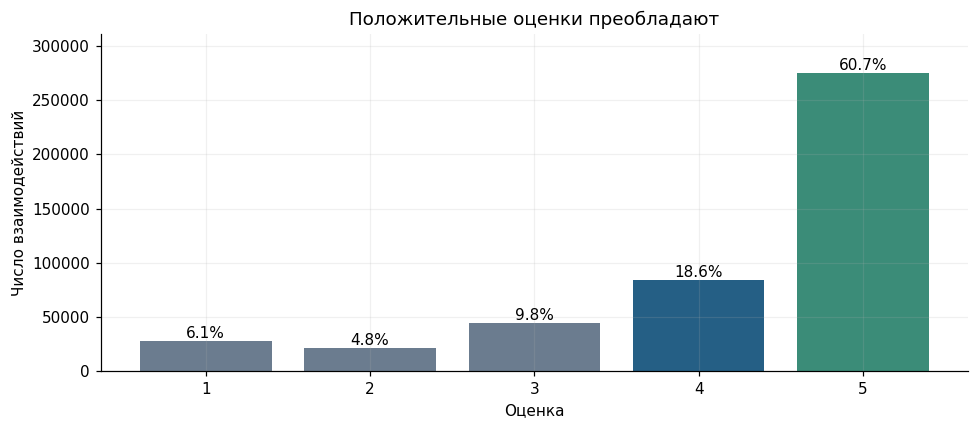

In [7]:
rating_counts = interactions.rating.value_counts().reindex(range(1, 6), fill_value=0)
positive_share = float((interactions.rating >= RELEVANCE_THRESHOLD).mean())
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(rating_counts.index.astype(str), rating_counts.values,
              color=[COLORS[4]]*3 + [COLORS[0], COLORS[2]])
for bar, count in zip(bars, rating_counts):
    ax.text(bar.get_x()+bar.get_width()/2, count, f'{count/len(interactions):.1%}',
            ha='center', va='bottom', fontsize=10)
ax.set(xlabel='Оценка', ylabel='Число взаимодействий',
       title='Положительные оценки преобладают', ylim=(0, rating_counts.max()*1.13))
show_figure('01_rating_distribution', fig)

Активность пользователей и популярность товаров.

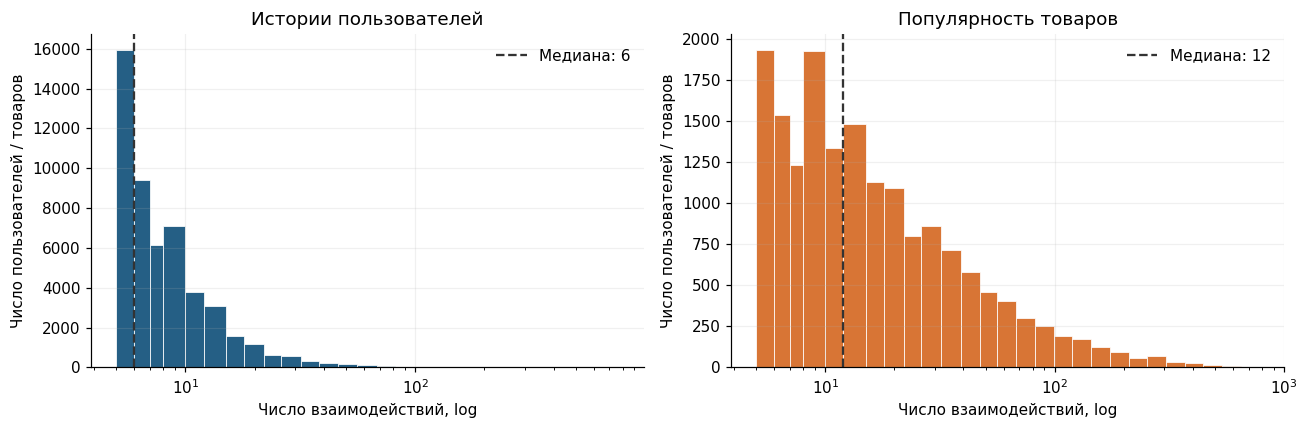

,Пользователи,Товары
count,50546.000000,16859.000000
mean,8.961916,26.869269
std,10.374768,46.099299
min,5.000000,5.000000
50%,6.000000,12.000000
90%,14.000000,57.000000
95%,20.000000,95.000000
99%,42.000000,247.420000
max,771.000000,777.000000


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, series, title, color in zip(axes,
        [user_activity, item_popularity], ['Истории пользователей', 'Популярность товаров'], COLORS):
    bins = np.unique(np.geomspace(5, series.max()+1, 28).astype(int))
    ax.hist(series, bins=bins, color=color, edgecolor='white', linewidth=.5)
    ax.set_xscale('log')
    ax.set(xlabel='Число взаимодействий, log', ylabel='Число пользователей / товаров', title=title)
    ax.axvline(series.median(), color='#333333', linestyle='--', label=f'Медиана: {series.median():g}')
    ax.legend(frameon=False)
show_figure('02_activity_and_popularity', fig)
display(pd.DataFrame({'Пользователи': user_activity.describe(percentiles=[.5,.9,.95,.99]),
                      'Товары': item_popularity.describe(percentiles=[.5,.9,.95,.99])}))

Доля взаимодействий у наиболее популярных товаров.

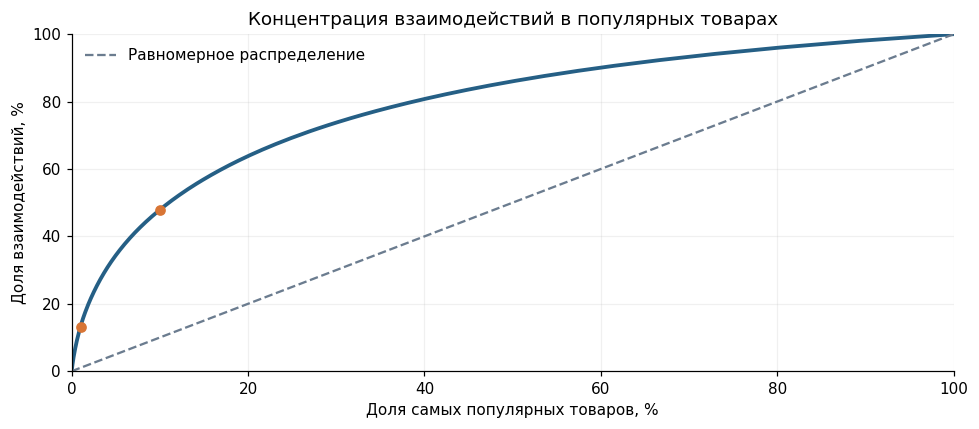

In [9]:
pop_sorted = item_popularity.sort_values(ascending=False)
cumulative = pop_sorted.cumsum() / pop_sorted.sum()
top_one_count = math.ceil(len(pop_sorted)*.01)
top_ten_count = math.ceil(len(pop_sorted)*.10)
top_one_share = float(cumulative.iloc[top_one_count-1])
top_ten_share = float(cumulative.iloc[top_ten_count-1])
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(np.arange(1, len(cumulative)+1)/len(cumulative)*100, cumulative.values*100, linewidth=2.5)
ax.plot([0,100], [0,100], '--', color=COLORS[4], label='Равномерное распределение')
ax.scatter([100*top_one_count/n_items, 100*top_ten_count/n_items],
           [top_one_share*100, top_ten_share*100], color=COLORS[1], zorder=3)
ax.set(xlabel='Доля самых популярных товаров, %', ylabel='Доля взаимодействий, %',
       title='Концентрация взаимодействий в популярных товарах', xlim=(0,100), ylim=(0,100))
ax.legend(frameon=False)
show_figure('03_popularity_concentration', fig)

12 товаров с наибольшим числом отзывов.

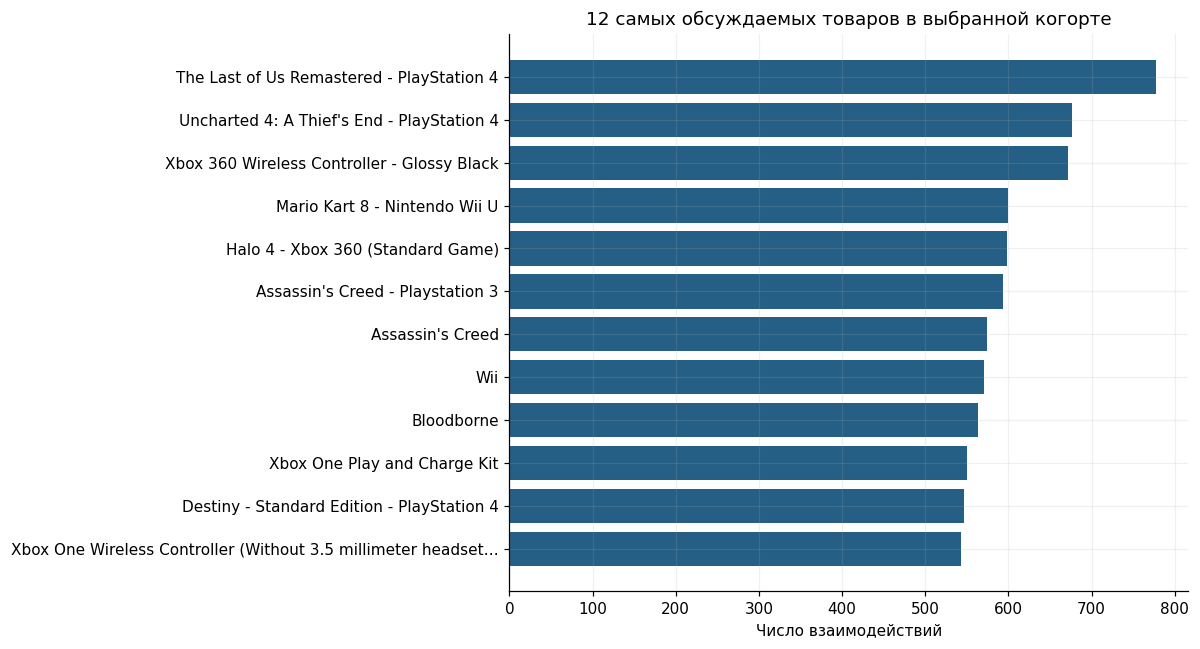

In [10]:
top_items = pop_sorted.head(12).rename('reviews').reset_index().merge(
    items[['item_id','title']], on='item_id', validate='one_to_one')
fig, ax = plt.subplots(figsize=(11, 6))
labels = [textwrap.shorten(t, width=65, placeholder='…') for t in top_items.title]
ax.barh(labels[::-1], top_items.reviews.iloc[::-1], color=COLORS[0])
ax.set(xlabel='Число взаимодействий', title='12 самых обсуждаемых товаров в выбранной когорте')
show_figure('04_top_items', fig)

Число отзывов по месяцам и годам, границы разбиения.

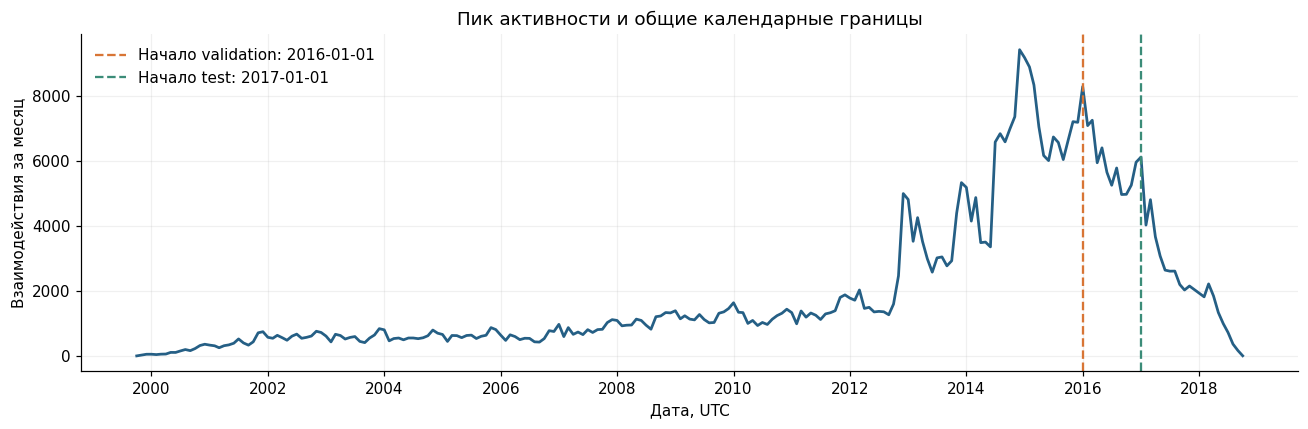

,Взаимодействия,Пользователи,Товары
datetime,,,
2011,16262,6455,4888
2012,22855,8333,6155
2013,43116,13753,8646
2014,68242,18838,10806
2015,85905,21997,12108
2016,72730,19776,11291
2017,37929,12347,8750
2018,11379,4777,4703


In [11]:
monthly = interactions.set_index('datetime').resample('MS').size()
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(monthly.index, monthly.values, color=COLORS[0], linewidth=1.8)
ax.axvline(VALIDATION_START, color=COLORS[1], linestyle='--', label='Начало validation: 2016-01-01')
ax.axvline(TEST_START, color=COLORS[2], linestyle='--', label='Начало test: 2017-01-01')
ax.set(xlabel='Дата, UTC', ylabel='Взаимодействия за месяц', title='Пик активности и общие календарные границы')
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.legend(frameon=False)
show_figure('05_monthly_activity', fig)
annual = interactions.groupby(interactions.datetime.dt.year).agg(
    interactions=('rating','size'), users=('user_id','nunique'), items=('item_id','nunique'))
display(annual.tail(8).rename(columns={'interactions':'Взаимодействия','users':'Пользователи','items':'Товары'}))

Длительность пользовательских историй и точность временных меток.

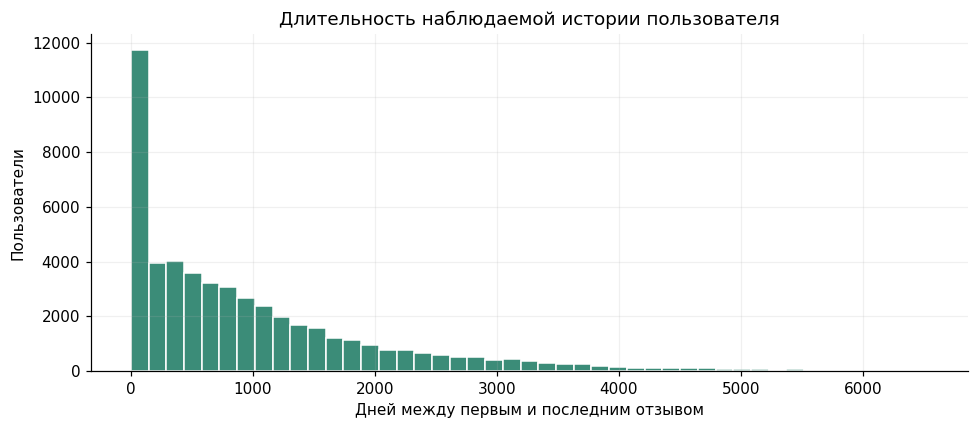

In [12]:
user_dates = interactions.groupby('user_id').datetime.agg(['min','max','nunique'])
spans = (user_dates['max']-user_dates['min']).dt.days
midnight_share = float((interactions.timestamp % 86400 == 0).mean())
same_day_share = float((spans==0).mean())
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(spans, bins=45, color=COLORS[2], edgecolor='white')
ax.set(xlabel='Дней между первым и последним отзывом', ylabel='Пользователи',
       title='Длительность наблюдаемой истории пользователя')
show_figure('06_user_history_duration', fig)

Заполненность полей метаданных.

,"Товары, %","Взаимодействия, %",Товаров без значения
Название,100.000000,100.000000,0.000000
Бренд,99.323803,99.712797,114.000000
Категории,99.128062,99.568422,147.000000
Описание,96.785100,97.674557,542.000000
Характеристики,87.662376,91.800905,2080.000000


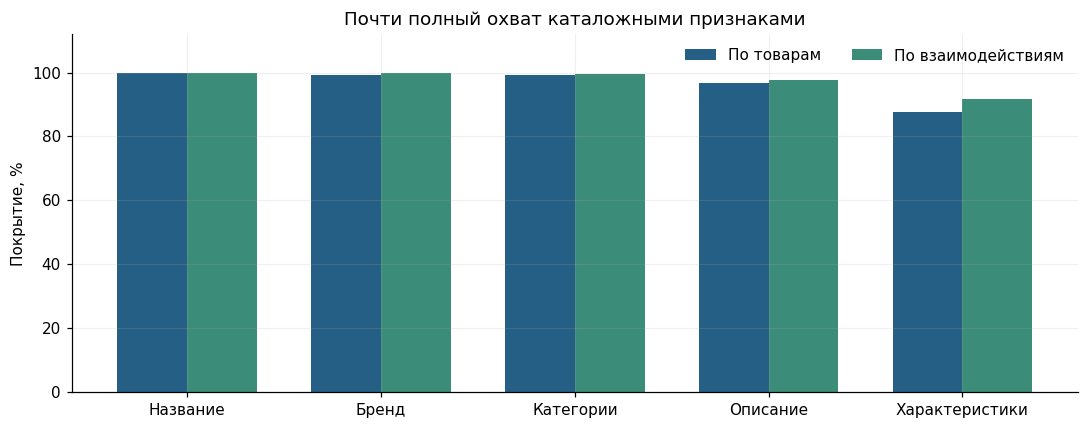

In [13]:
fields = ['title','brand','categories','description','features']
field_labels = ['Название','Бренд','Категории','Описание','Характеристики']
coverage = pd.DataFrame(index=fields)
for field in fields:
    present = items[field].map(bool)
    coverage.loc[field,'Товары, %'] = present.mean()*100
    weighted = items.item_id.map(item_popularity).fillna(0)
    coverage.loc[field,'Взаимодействия, %'] = weighted[present].sum()/len(interactions)*100
    coverage.loc[field,'Товаров без значения'] = (~present).sum()
coverage.index = field_labels
display(coverage)
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(fields)); width=.36
ax.bar(x-width/2, coverage['Товары, %'], width, label='По товарам', color=COLORS[0])
ax.bar(x+width/2, coverage['Взаимодействия, %'], width, label='По взаимодействиям', color=COLORS[2])
ax.set_xticks(x, field_labels)
ax.set(ylabel='Покрытие, %', ylim=(0,112), title='Почти полный охват каталожными признаками')
ax.legend(frameon=False, ncols=2)
show_figure('07_metadata_coverage', fig)

Частоты брендов и категорий.

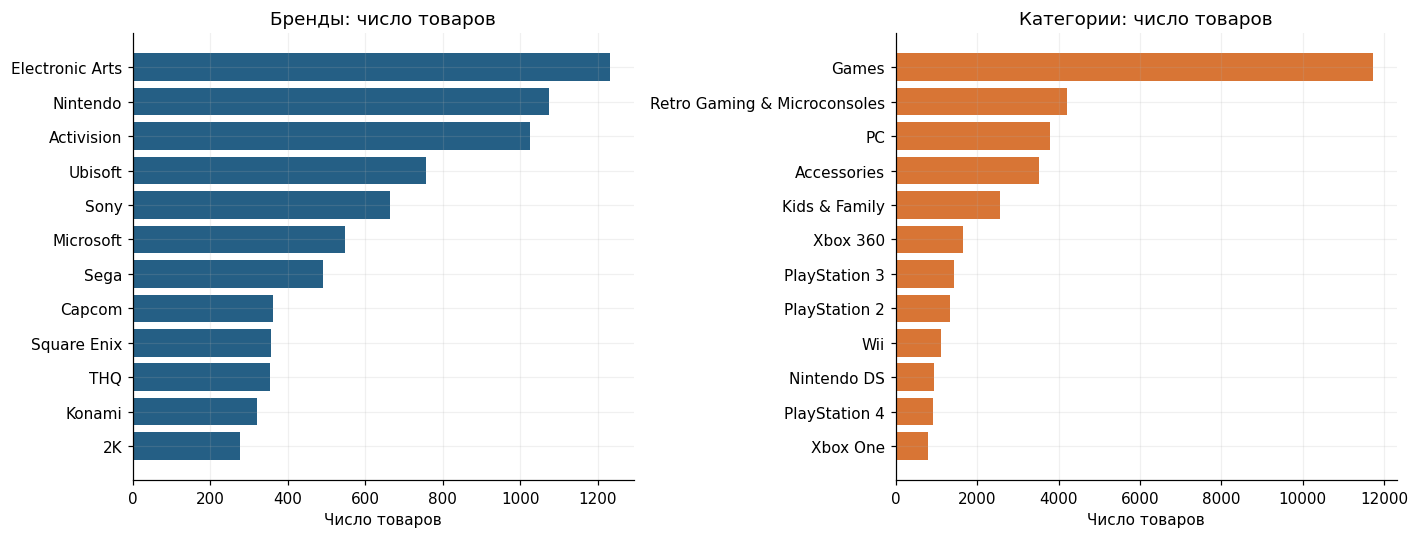

In [14]:
brand_counts = items.loc[items.brand.map(bool),'brand'].value_counts()
category_counts = items[['item_id','categories']].explode('categories').dropna().query(
    "categories != 'Video Games'").categories.value_counts()
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, values, title, color in zip(axes, [brand_counts.head(12), category_counts.head(12)],
        ['Бренды: число товаров', 'Категории: число товаров'], COLORS):
    labels=[textwrap.shorten(str(s), width=29, placeholder='…') for s in values.index]
    ax.barh(labels[::-1], values.iloc[::-1], color=color)
    ax.set(xlabel='Число товаров', title=title)
show_figure('08_brands_and_categories', fig)

Длины текстовых полей и повторные названия товаров.

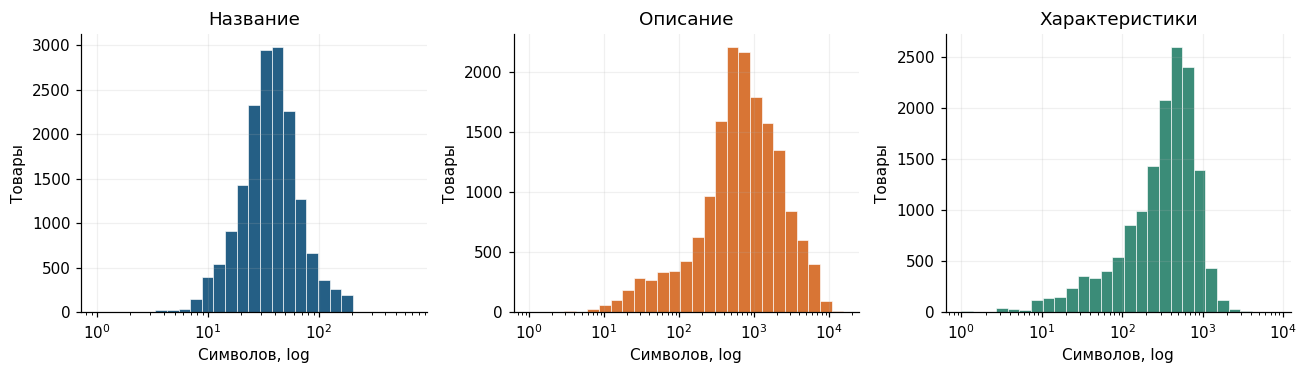

,Название,Описание,Характеристики
count,16859.000000,16859.000000,16859.000000
mean,43.100000,1168.400000,381.000000
std,29.900000,1437.300000,363.200000
min,3.000000,0.000000,0.000000
50%,36.000000,660.000000,321.000000
90%,73.200000,2862.400000,823.200000
99%,164.000000,6843.900000,1519.400000
max,679.000000,15438.000000,7988.000000


In [15]:
text_lengths = pd.DataFrame({
    'Название': items.title.str.len(),
    'Описание': items.description.map(lambda x: len(' '.join(x))),
    'Характеристики': items.features.map(lambda x: len(' '.join(x))),
})
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, (field, values), color in zip(axes, text_lengths.items(), COLORS):
    nonempty=values[values>0]
    bins=np.geomspace(1, nonempty.max()+1, 28)
    ax.hist(nonempty, bins=bins, color=color, edgecolor='white', linewidth=.4)
    ax.set_xscale('log')
    ax.set(xlabel='Символов, log', ylabel='Товары', title=field)
show_figure('09_text_lengths', fig)
normalized_titles=items.title.str.casefold().str.replace(r'\W+', ' ', regex=True).str.strip()
title_groups=normalized_titles.value_counts()
duplicate_title_items=int(normalized_titles.isin(title_groups[title_groups>1].index).sum())
display(text_lengths.describe(percentiles=[.5,.9,.99]).round(1))

Временные границы, размеры выборок и отсутствие пересечений.

In [16]:
train = interactions[interactions.datetime < VALIDATION_START].copy()
validation = interactions[(interactions.datetime >= VALIDATION_START) &
                           (interactions.datetime < TEST_START)].copy()
test = interactions[interactions.datetime >= TEST_START].copy()
final_fit = pd.concat([train, validation], ignore_index=True)
partitions={'train':train, 'validation':validation, 'test':test}
assert len(train)+len(validation)+len(test) == len(interactions)
assert train.datetime.max() < validation.datetime.min()
assert validation.datetime.max() < test.datetime.min()
assert final_fit.datetime.max() < test.datetime.min()
assert not train.index.intersection(validation.index).size
assert not train.index.intersection(test.index).size
assert not validation.index.intersection(test.index).size
split_rows=[]
for name, frame in partitions.items():
    split_rows.append({'Выборка':name, 'Взаимодействия':len(frame),
        'Доля, %':100*len(frame)/len(interactions), 'Пользователи':frame.user_id.nunique(),
        'Товары':frame.item_id.nunique(), 'Первая дата':frame.datetime.min().strftime('%Y-%m-%d'),
        'Последняя дата':frame.datetime.max().strftime('%Y-%m-%d')})
split_table=pd.DataFrame(split_rows).set_index('Выборка')
display(split_table)

,Взаимодействия,"Доля, %",Пользователи,Товары,Первая дата,Последняя дата
Выборка,,,,,,
train,330951,73.059390,43463,15578,1999-10-14,2015-12-31
validation,72730,16.055578,19776,11291,2016-01-01,2016-12-31
test,49308,10.885033,14735,9766,2017-01-01,2018-10-02


Протокол оценки и выводы EDA.

In [17]:
protocol = {
    'validation_start': VALIDATION_START.isoformat(), 'test_start': TEST_START.isoformat(),
    'selection': 'maximum validation macro NDCG@10', 'k': K, 'relevance': 'rating >= 4',
    'candidates': 'full fit catalog minus all observed fit items',
    'cohort': 'known users; at least one unseen relevant fit item and at least K candidates',
    'ties': 'item ID ascending', 'fallback': 'fit positive popularity; whole user if unavailable scores',
    'bootstrap': {'resamples':2000, 'seed':SEED, 'confidence':.95},
    'test_status': 'previously observed; reproduction, not a new independent holdout',
}
display(pd.Series(protocol, name='Протокол').to_frame())
display(Markdown(f'Разреженность: **{1-density:.3%}**. Оценки 4–5: **{positive_share:.1%}**. '
    f'Доля событий верхних 10% товаров: **{top_ten_share:.1%}**. '
    f'Временные метки на 00:00 UTC: **{midnight_share:.1%}**.\n\n'
    'Каталожные поля — только EDA. Признаки FM — история до момента рекомендации. '
    'Ограничения: 5-core и наличие названия по всей выгрузке, отзывы вместо показов, '
    'только известные пользователи и товары, разные длительности validation и test.'))

,Протокол
validation_start,2016-01-01T00:00:00+00:00
test_start,2017-01-01T00:00:00+00:00
selection,maximum validation macro NDCG@10
k,10
relevance,rating >= 4
candidates,full fit catalog minus all observed fit items
cohort,known users; at least one unseen relevant fit ...
ties,item ID ascending
fallback,fit positive popularity; whole user if unavail...
bootstrap,"{'resamples': 2000, 'seed': 42, 'confidence': ..."


Разреженность: **99.947%**. Оценки 4–5: **79.3%**. Доля событий верхних 10% товаров: **47.9%**. Временные метки на 00:00 UTC: **100.0%**.

Каталожные поля — только EDA. Признаки FM — история до момента рекомендации. Ограничения: 5-core и наличие названия по всей выгрузке, отзывы вместо показов, только известные пользователи и товары, разные длительности validation и test.

Общий оценщик, сетки параметров, правила выбора и функции обучения.

In [18]:
SEARCH = {'ItemKNN': {'model': 'ItemKNN',
             'feedback': 'binary: fit rating >= 4',
             'similarity': 'cosine * overlap / (overlap + shrinkage)',
             'neighborhood': 'top neighbors per target item; no self-neighbors',
             'grid': {'n_neighbors': [20, 50, 100, 200], 'shrinkage': [0.0, 10.0, 50.0]},
             'selection': 'maximum validation macro NDCG@10',
             'tie_break': 'fewer neighbors, then smaller shrinkage; no secondary-metric selection',
             'budget': 12,
             'seed': 42,
             'no_evidence': 'no positive evidence for any unseen candidate -> shared popularity '
                            'fallback'},
 'iALS': {'model': 'iALS',
          'preference': 'p_ui = 1 for fit rating >= 4; otherwise 0',
          'confidence': 'c_ui = 1 + alpha * p_ui, including c=1 on unobserved pairs',
          'regularization': 'lambda * (sum user squared norms + sum item squared norms); not '
                            'degree-scaled',
          'grid': {'n_factors': [16, 32, 64], 'alpha': [10.0, 40.0], 'regularization': [0.1, 1.0]},
          'n_iterations': 15,
          'seed': 42,
          'solver_batch_size': 128,
          'budget': 12,
          'selection': 'maximum validation macro NDCG@10',
          'tie_break': 'fewer factors, then smaller alpha, then larger regularization',
          'early_stopping': False,
          'test_evaluated': False},
 'EASE': {'model': 'EASE',
          'preference': 'X_ui=1 for fit rating >=4; otherwise 0',
          'objective': '||X-XB||_F^2 + lambda*||B||_F^2, diag(B)=0; unnormalized sum loss',
          'grid': {'regularization': [1.0, 10.0, 30.0, 100.0, 300.0, 1000.0, 10000.0]},
          'budget': 7,
          'selection': 'maximum validation macro NDCG@10',
          'tie_break': 'larger regularization',
          'dtype': 'float64',
          'approximation': 'none; full dense signed matrix, no pruning or clipping',
          'test_evaluated': False},
 'FM': {'model': 'FM',
        'grid': {'n_factors': [16, 32],
                 'learning_rate': [0.05, 0.15],
                 'regularization': [1e-05, 0.001]},
        'budget': 8,
        'n_epochs': 12,
        'batch_size': 1024,
        'seed': 42,
        'shuffle_seed': 43,
        'negative_sampling_seed': 137,
        'negatives_per_positive': 2,
        'minimum_items_per_metadata_token': 5,
        'features': 'user ID, item ID; timestamp-derived item metadata: first observed review '
                    'year/month; log1p(fit event count)/log1p(1000), log1p(history age '
                    'days)/log1p(3650), log1p(recency days)/log1p(3650)',
        'metadata_assumption': 'No crawl-time fields or review text. Features derive solely from '
                               'fit IDs and timestamps strictly before the frozen query; no rating '
                               'values used in metadata.',
        'loss': 'mean logistic loss; observed rating>=4 positive, observed 1-3 negative, sampled '
                'unobserved negative',
        'regularization': 'reg/2 times mean sum_active x_j^2*(w_j^2+||v_j||^2); feature-frequency '
                          'weighted, bias unregularized',
        'optimizer': 'mini-batch sparse AdaGrad, gradient summed per repeated feature before '
                     'accumulator update; epsilon 1e-8',
        'negative_sampling': 'uniform with replacement from fit catalog excluding ALL observed fit '
                             'pairs; frozen across epochs and trials; no future exclusion',
        'selection': 'maximum validation macro NDCG@10 after all 12 epochs',
        'tie_break': 'fewer factors, then smaller learning rate, then larger regularization',
        'early_stopping': False,
        'metadata_ablation': 'fixed ID-only run at selected metadata-FM hyperparameters; '
                             'diagnostic only',
        'test_evaluated': False,
        'experiment_version': 'temporal_metadata_v2'},
 'timeSVD++': {'model': 'timeSVD++',
               'grid': {'n_factors': [16, 32], 'n_bins': [12, 36], 'regularization': [0.01, 0.1]},
               'budget': 8,
               'learning_rate': 0.05,
               'n_epochs': 50,
               'beta': 0.4,
               'seed': 42,
               'target': 'original observed ratings 1..5; no negative sampling, no score clipping',
               'implicit_history': 'all observed fit items, including the rated target in fit, '
                                   'normalized by sqrt(history size); frozen at query',
               'time': 'UTC integer Unix days; fit-only per-user mean; '
                       'dev=sign((day-mean)/365.25)*abs((day-mean)/365.25)^beta',
               'item_bins': 'equal-width over fit min_day..max_day inclusive; queries outside fit '
                            'range clipped to nearest edge bin',
               'unseen_user_day': 'day bias and day factor are zero for unobserved (user, day); no '
                                  'extrapolation of day effects',
               'loss': 'one half mean squared rating error + regularization/2 times '
                       'per-observation active-parameter squared norms; implicit Y penalty '
                       'averages squared history coefficients',
               'optimizer': 'exact full-gradient AdaGrad, one full-data step per epoch, epsilon '
                            '1e-8; H@Y and H.T@g exact, no stale-epoch history approximation',
               'selection': 'maximum validation macro NDCG@10 at fixed stage query time after all '
                            '50 epochs',
               'tie_break': 'fewer factors, then fewer bins, then larger regularization',
               'early_stopping': False,
               'temporal_ablation': 'one additional static SVD++ run with selected '
                                    'hyperparameters, temporal terms disabled; diagnostic only, '
                                    'not separately tuned',
               'test_evaluated': False}}
FIXED = {
    'ItemKNN': {}, 'iALS': {'n_iterations':15, 'seed':SEED, 'solver_batch_size':128},
    'EASE': {}, 'FM': {'n_epochs':12, 'batch_size':1024, 'seed':SEED, 'shuffle_seed':43},
    'timeSVD++': {'learning_rate':.05, 'n_epochs':50, 'beta':.4, 'seed':SEED},
}
TIES = {'ItemKNN':(['n_neighbors','shrinkage'],[True,True]),
        'iALS':(['n_factors','alpha','regularization'],[True,True,False]),
        'EASE':(['regularization'],[False]),
        'FM':(['n_factors','learning_rate','regularization'],[True,True,False]),
        'timeSVD++':(['n_factors','n_bins','regularization'],[True,True,False])}
MODEL_NAMES = list(SEARCH)
train_data = FitData.from_frame(train)
validation_context = EvaluationContext.from_frames(train, validation, fit_data=train_data,
                            k=K, query_timestamp=int(VALIDATION_START.timestamp()))
validation_results = {'Popularity': evaluate_popularity(validation_context)}
searches, best_parameters, best_curves, best_diagnostics, search_specs = {}, {}, {}, {}, {}
fit_log = []
fm_cache = {}

def fit_model(name, parameters, frame, data, query, *, stage, use_metadata=True, temporal=True):
    assert data.max_timestamp < query
    started = time.perf_counter()
    diagnostics = {}
    curve = pd.DataFrame()
    if name == 'ItemKNN':
        model = ItemKNN(**parameters).fit(data)
    elif name == 'EASE':
        model = EASE(**parameters).fit(data)
        diagnostics = model.diagnostics_.copy()
    elif name == 'iALS':
        model = IALS(**parameters).fit(data)
        curve = pd.DataFrame({'epoch':range(len(model.loss_history_)), 'objective':model.loss_history_})
    elif name == 'FM':
        cache_key = (data.fingerprint, query, use_metadata)
        if cache_key not in fm_cache:
            features = MetadataFeatures.from_history(data, frame, query, minimum_items=5, use_metadata=use_metadata)
            examples = sample_training(data, frame, negatives_per_positive=2, seed=137)
            fm_cache[cache_key] = (features, examples)
        features, examples = fm_cache[cache_key]
        assert features.diagnostics['all_source_timestamps_before_query']
        model = FM(**parameters).fit(data, features, examples)
        diagnostics = {**features.diagnostics, **examples[3]}
        curve = pd.DataFrame(model.curve_)
    elif name == 'timeSVD++':
        model = TimeSVDpp(**parameters, temporal=temporal).fit(data, frame)
        curve = pd.DataFrame(model.curve_)
    else:
        raise ValueError(name)
    seconds = time.perf_counter()-started
    fit_log.append({'model':name, 'stage':stage, 'fit_fingerprint':data.fingerprint,
                    'fit_seconds':seconds, 'parameters':dict(parameters),
                    'query_timestamp':query, 'max_fit_timestamp':data.max_timestamp})
    return model, seconds, curve, diagnostics

def validation_search(name):
    spec = {'grid': SEARCH[name]['grid'], 'fixed': FIXED[name]}
    search_specs[name] = json.loads(json.dumps(spec))
    keys = list(spec['grid'])
    combinations = list(itertools.product(*(spec['grid'][key] for key in keys)))
    assert len(combinations) == SEARCH[name]['budget']
    records, winner_key, winner = [], None, None
    tie_names, tie_ascending = TIES[name]
    for trial, values in enumerate(combinations, 1):
        parameters = {**FIXED[name], **dict(zip(keys, values))}
        print(f'{name}: {trial}/{len(combinations)} — {parameters}', flush=True)
        model, seconds, curve, diagnostics = fit_model(name, parameters, train, train_data,
                  validation_context.query_timestamp, stage='validation')
        result = evaluate_model(model, validation_context, batch_size=128)
        assert np.isfinite([result.metrics['ndcg_at_10'],result.metrics['recall_at_10']]).all()
        records.append({'trial':trial, **parameters, **result.metrics, 'fit_seconds':seconds})
        key = (-result.metrics['ndcg_at_10'], *(parameters[p] if asc else -parameters[p]
                                               for p,asc in zip(tie_names,tie_ascending)))
        if winner_key is None or key < winner_key:
            winner_key, winner = key, dict(parameters)
            validation_results[name] = result
            best_curves[name], best_diagnostics[name] = curve.copy(), diagnostics.copy()
        print(f"NDCG@10={result.metrics['ndcg_at_10']:.6f}; Recall@10={result.metrics['recall_at_10']:.6f}", flush=True)
        del model
        gc.collect()
    searches[name] = pd.DataFrame(records).sort_values(['ndcg_at_10']+tie_names,
                                        ascending=[False]+tie_ascending, kind='stable')
    best_parameters[name] = winner
    searches[name].to_csv(RUN/f'{name.replace("+", "p")}_validation.csv', index=False)
    display(searches[name])
    display(pd.Series(winner, name='Лучшие параметры').to_frame())

def plot_search(name):
    table = searches[name].sort_values('trial')
    fig, axes = plt.subplots(1,2,figsize=(11,3.5))
    for ax, metric in zip(axes, ['ndcg_at_10','recall_at_10']):
        ax.plot(table.trial, table[metric], 'o-')
        ax.set(xlabel='Номер конфигурации', ylabel=metric, title=f'{name}: validation')
    show_figure(name, fig)
    curve = best_curves[name]
    if not curve.empty:
        columns = {'iALS':['objective'], 'FM':['probe_bce','probe_objective'],
                   'timeSVD++':['training_rmse','training_objective']}[name]
        fig, axes = plt.subplots(1,len(columns),figsize=(6*len(columns),3.5),squeeze=False)
        for ax, column in zip(axes[0],columns):
            ax.plot(curve.epoch,curve[column])
            ax.set(xlabel='Шаг обучения',ylabel=column,title=name)
        show_figure(name+'_training',fig)
    display(pd.DataFrame([{'model':n,**r.metrics} for n,r in validation_results.items()]).set_index('model'))
    display(history_slices(validation_results[name]))
    display(popularity_slices(validation_results[name], validation_context))

(RUN/'protocol.json').write_text(json.dumps(protocol,ensure_ascii=False,indent=2))
(RUN/'search_plan.json').write_text(json.dumps({'search':SEARCH,'fixed':FIXED},ensure_ascii=False,indent=2))
display(pd.Series(validation_context.diagnostics, name='Validation').to_frame())

,Validation
evaluation_users,10207
catalog_items,15578
relevant_interactions,25646
seen_relevant_items_removed,0
users_excluded_for_fewer_than_k_candidates,0
new_user_interactions,28223
new_item_interactions,16949


## ItemKNN

Сетка параметров и подбор по validation NDCG@10.

In [19]:
display(pd.Series(SEARCH['ItemKNN'], name='Параметры').to_frame())
validation_search('ItemKNN')

,Параметры
model,ItemKNN
feedback,binary: fit rating >= 4
similarity,cosine * overlap / (overlap + shrinkage)
neighborhood,top neighbors per target item; no self-neighbors
grid,"{'n_neighbors': [20, 50, 100, 200], 'shrinkage..."
selection,maximum validation macro NDCG@10
tie_break,"fewer neighbors, then smaller shrinkage; no se..."
budget,12
seed,42
no_evidence,no positive evidence for any unseen candidate ...


ItemKNN: 1/12 — {'n_neighbors': 20, 'shrinkage': 0.0}


NDCG@10=0.015070; Recall@10=0.022635


ItemKNN: 2/12 — {'n_neighbors': 20, 'shrinkage': 10.0}


NDCG@10=0.020710; Recall@10=0.031267


...

NDCG@10=0.021053; Recall@10=0.031936


ItemKNN: 12/12 — {'n_neighbors': 200, 'shrinkage': 50.0}


NDCG@10=0.020942; Recall@10=0.032029


,trial,n_neighbors,shrinkage,ndcg_at_10,recall_at_10,catalog_coverage_at_10,fallback_rate,users,evaluation_seconds,fit_seconds
7,8,100,10.000000,0.021111,0.032179,0.738798,0.051435,10207,1.194325,0.351248
10,11,200,10.000000,0.021053,0.031936,0.734369,0.051435,10207,1.363887,0.399317
4,5,50,10.000000,0.021031,0.032057,0.746566,0.051435,10207,1.038963,0.295710
11,12,200,50.000000,0.020942,0.032029,0.711516,0.051435,10207,1.377963,0.405922
8,9,100,50.000000,0.020885,0.031872,0.715753,0.051435,10207,1.184862,0.338125
5,6,50,50.000000,0.020839,0.031999,0.725510,0.051435,10207,1.048726,0.292942
1,2,20,10.000000,0.020710,0.031267,0.765695,0.051533,10207,0.989310,0.246982
2,3,20,50.000000,0.020543,0.031112,0.748042,0.051533,10207,0.999809,0.252285
9,10,200,0.000000,0.015092,0.022641,0.854988,0.051435,10207,1.343714,0.390534
0,1,20,0.000000,0.015070,0.022635,0.857235,0.051533,10207,0.972407,0.261160


,Лучшие параметры
n_neighbors,100.000000
shrinkage,10.000000


Метрики validation, кривая обучения и срезы качества.

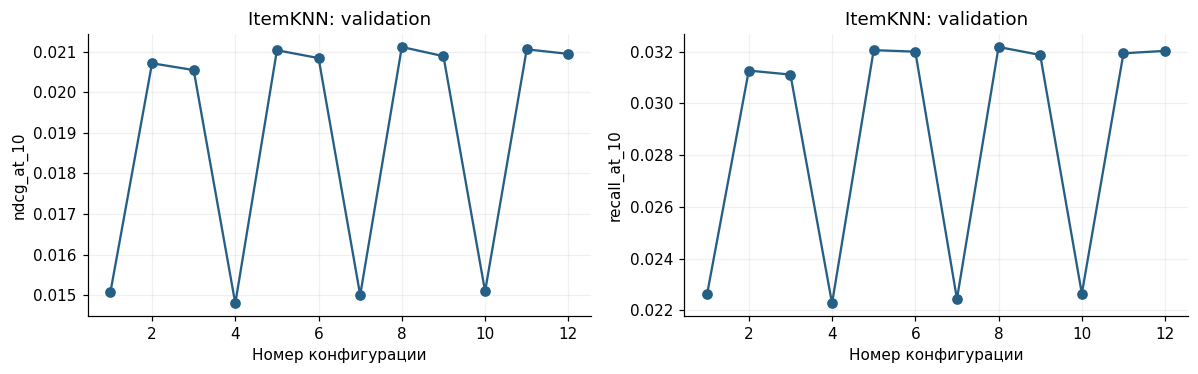

,ndcg_at_10,recall_at_10,catalog_coverage_at_10,fallback_rate,users,evaluation_seconds
model,,,,,,
Popularity,0.005779,0.010252,0.000963,0.000000,10207,1.129206
ItemKNN,0.021111,0.032179,0.738798,0.051435,10207,1.194325


,users,ndcg,recall,fallback_rate
history_slice,,,,
1-4,5943,0.021634,0.032072,0.086152
5-9,2766,0.019806,0.033355,0.004700
10+,1498,0.021447,0.030435,0.000000


,users,relevant_interactions,recall_at_10
item_slice,,,
head_top_10_percent,5704,10248,0.056922
tail_other_90_percent,7765,15398,0.014238


In [20]:
plot_search('ItemKNN')

## iALS

Сетка параметров и подбор по validation NDCG@10.

In [21]:
display(pd.Series(SEARCH['iALS'], name='Параметры').to_frame())
validation_search('iALS')

,Параметры
model,iALS
preference,p_ui = 1 for fit rating >= 4; otherwise 0
confidence,"c_ui = 1 + alpha * p_ui, including c=1 on unob..."
regularization,lambda * (sum user squared norms + sum item sq...
grid,"{'n_factors': [16, 32, 64], 'alpha': [10.0, 40..."
n_iterations,15
seed,42
solver_batch_size,128
budget,12
selection,maximum validation macro NDCG@10


iALS: 1/12 — {'n_iterations': 15, 'seed': 42, 'solver_batch_size': 128, 'n_factors': 16, 'alpha': 10.0, 'regularization': 0.1}


NDCG@10=0.016947; Recall@10=0.027606


iALS: 2/12 — {'n_iterations': 15, 'seed': 42, 'solver_batch_size': 128, 'n_factors': 16, 'alpha': 10.0, 'regularization': 1.0}


NDCG@10=0.016848; Recall@10=0.027345


...

NDCG@10=0.021893; Recall@10=0.034360


iALS: 12/12 — {'n_iterations': 15, 'seed': 42, 'solver_batch_size': 128, 'n_factors': 64, 'alpha': 40.0, 'regularization': 1.0}


NDCG@10=0.021805; Recall@10=0.034215


,trial,n_iterations,seed,solver_batch_size,n_factors,alpha,regularization,ndcg_at_10,recall_at_10,catalog_coverage_at_10,fallback_rate,users,evaluation_seconds,fit_seconds
10,11,15,42,128,64,40.000000,0.100000,0.021893,0.034360,0.143215,0.050260,10207,1.483479,41.584411
11,12,15,42,128,64,40.000000,1.000000,0.021805,0.034215,0.143728,0.050260,10207,1.490906,41.758940
9,10,15,42,128,64,10.000000,1.000000,0.021663,0.034499,0.090320,0.050260,10207,1.475653,41.669923
8,9,15,42,128,64,10.000000,0.100000,0.021652,0.034341,0.090833,0.050260,10207,1.502647,41.442785
7,8,15,42,128,32,40.000000,1.000000,0.021022,0.032723,0.088330,0.050260,10207,1.469006,10.826502
6,7,15,42,128,32,40.000000,0.100000,0.020868,0.032795,0.087367,0.050260,10207,1.478896,11.079434
4,5,15,42,128,32,10.000000,0.100000,0.020407,0.032499,0.054693,0.050260,10207,1.507126,10.971096
5,6,15,42,128,32,10.000000,1.000000,0.020331,0.032371,0.054500,0.050260,10207,1.552561,10.937243
2,3,15,42,128,16,40.000000,0.100000,0.018547,0.030460,0.050135,0.050260,10207,1.465372,3.023501
3,4,15,42,128,16,40.000000,1.000000,0.018469,0.030347,0.050006,0.050260,10207,1.454554,3.027640


,Лучшие параметры
n_iterations,15.000000
seed,42.000000
solver_batch_size,128.000000
n_factors,64.000000
alpha,40.000000
regularization,0.100000


Метрики validation, кривая обучения и срезы качества.

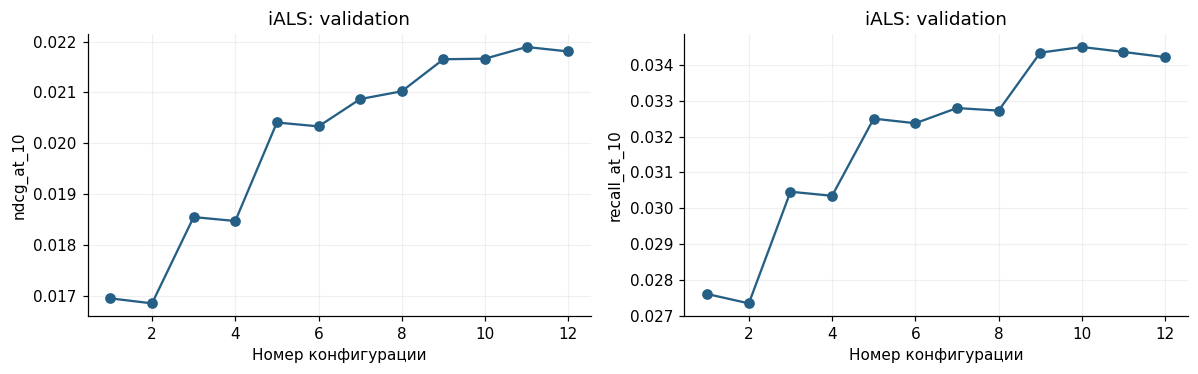

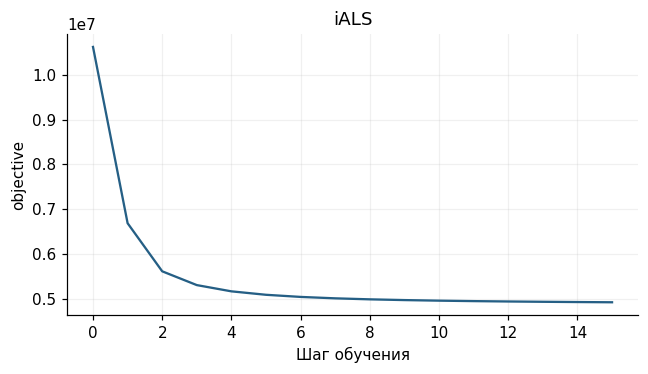

,ndcg_at_10,recall_at_10,catalog_coverage_at_10,fallback_rate,users,evaluation_seconds
model,,,,,,
Popularity,0.005779,0.010252,0.000963,0.000000,10207,1.129206
ItemKNN,0.021111,0.032179,0.738798,0.051435,10207,1.194325
iALS,0.021893,0.034360,0.143215,0.050260,10207,1.483479


,users,ndcg,recall,fallback_rate
history_slice,,,,
1-4,5943,0.022691,0.034203,0.084133
5-9,2766,0.021001,0.037281,0.004700
10+,1498,0.020377,0.029589,0.000000


,users,relevant_interactions,recall_at_10
item_slice,,,
head_top_10_percent,5704,10248,0.081696
tail_other_90_percent,7765,15398,0.002851


In [22]:
plot_search('iALS')

## EASE

Сетка параметров и подбор по validation NDCG@10.

In [23]:
display(pd.Series(SEARCH['EASE'], name='Параметры').to_frame())
validation_search('EASE')

,Параметры
model,EASE
preference,X_ui=1 for fit rating >=4; otherwise 0
objective,"||X-XB||_F^2 + lambda*||B||_F^2, diag(B)=0; un..."
grid,"{'regularization': [1.0, 10.0, 30.0, 100.0, 30..."
budget,7
selection,maximum validation macro NDCG@10
tie_break,larger regularization
dtype,float64
approximation,"none; full dense signed matrix, no pruning or ..."
test_evaluated,False


EASE: 1/7 — {'regularization': 1.0}


NDCG@10=0.017876; Recall@10=0.026578


EASE: 2/7 — {'regularization': 10.0}


NDCG@10=0.021882; Recall@10=0.033175


...

NDCG@10=0.022120; Recall@10=0.033417


EASE: 7/7 — {'regularization': 10000.0}


NDCG@10=0.021387; Recall@10=0.032597


,trial,regularization,ndcg_at_10,recall_at_10,catalog_coverage_at_10,fallback_rate,users,evaluation_seconds,fit_seconds
3,4,100.000000,0.023372,0.035191,0.497689,0.051435,10207,1.704717,16.787791
2,3,30.000000,0.023062,0.034908,0.543459,0.051435,10207,1.691024,16.693803
4,5,300.000000,0.022912,0.034628,0.483053,0.051435,10207,1.745348,16.287164
5,6,1000.000000,0.022120,0.033417,0.484337,0.051435,10207,1.749717,16.070243
1,2,10.000000,0.021882,0.033175,0.627038,0.051435,10207,1.704923,16.588987
6,7,10000.000000,0.021387,0.032597,0.489986,0.051435,10207,1.746894,16.232293
0,1,1.000000,0.017876,0.026578,0.738927,0.051435,10207,1.741840,16.355623


,Лучшие параметры
regularization,100.000000


Метрики validation, кривая обучения и срезы качества.

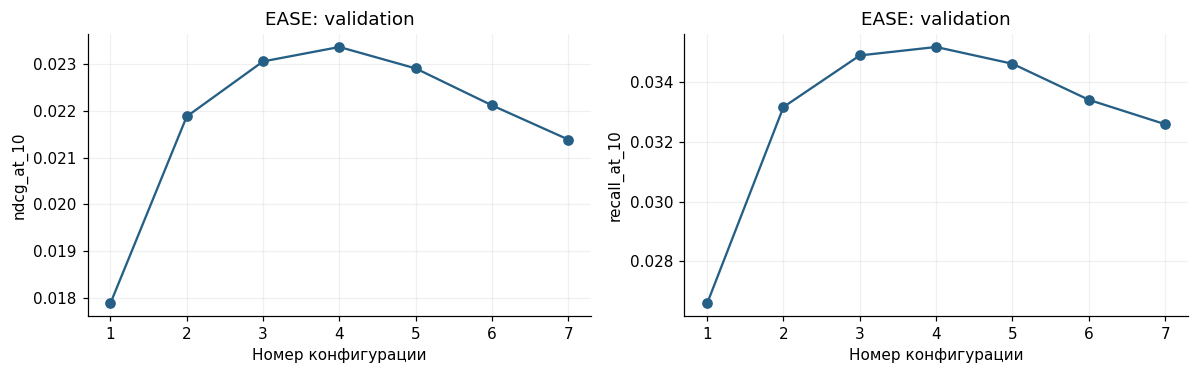

,ndcg_at_10,recall_at_10,catalog_coverage_at_10,fallback_rate,users,evaluation_seconds
model,,,,,,
Popularity,0.005779,0.010252,0.000963,0.000000,10207,1.129206
ItemKNN,0.021111,0.032179,0.738798,0.051435,10207,1.194325
iALS,0.021893,0.034360,0.143215,0.050260,10207,1.483479
EASE,0.023372,0.035191,0.497689,0.051435,10207,1.704717


,users,ndcg,recall,fallback_rate
history_slice,,,,
1-4,5943,0.023352,0.034353,0.086152
5-9,2766,0.023400,0.039595,0.004700
10+,1498,0.023397,0.030388,0.000000


,users,relevant_interactions,recall_at_10
item_slice,,,
head_top_10_percent,5704,10248,0.068608
tail_other_90_percent,7765,15398,0.011670


In [24]:
plot_search('EASE')

Размер матрицы и статистика весов EASE.

In [25]:
display(pd.Series(best_diagnostics['EASE'],name='EASE').to_frame())

,EASE
catalog_items,15578.000000
weight_bytes,1941392672.000000
nonzero_weights,237853506.000000
negative_weights,110083966.000000
negative_fraction_of_nonzero,0.462823
training_objective,233191.091650


## FM

Сетка параметров и подбор по validation NDCG@10.

In [26]:
display(pd.Series(SEARCH['FM'], name='Параметры').to_frame())
validation_search('FM')

,Параметры
model,FM
grid,"{'n_factors': [16, 32], 'learning_rate': [0.05..."
budget,8
n_epochs,12
batch_size,1024
seed,42
shuffle_seed,43
negative_sampling_seed,137
negatives_per_positive,2
minimum_items_per_metadata_token,5


FM: 1/8 — {'n_epochs': 12, 'batch_size': 1024, 'seed': 42, 'shuffle_seed': 43, 'n_factors': 16, 'learning_rate': 0.05, 'regularization': 1e-05}


NDCG@10=0.005808; Recall@10=0.009718


FM: 2/8 — {'n_epochs': 12, 'batch_size': 1024, 'seed': 42, 'shuffle_seed': 43, 'n_factors': 16, 'learning_rate': 0.05, 'regularization': 0.001}


NDCG@10=0.005391; Recall@10=0.009019


...

NDCG@10=0.003882; Recall@10=0.006454


FM: 8/8 — {'n_epochs': 12, 'batch_size': 1024, 'seed': 42, 'shuffle_seed': 43, 'n_factors': 32, 'learning_rate': 0.15, 'regularization': 0.001}


NDCG@10=0.003559; Recall@10=0.005998


,trial,n_epochs,batch_size,seed,shuffle_seed,n_factors,learning_rate,regularization,ndcg_at_10,recall_at_10,catalog_coverage_at_10,fallback_rate,users,evaluation_seconds,fit_seconds
0,1,12,1024,42,43,16,0.050000,0.000010,0.005808,0.009718,0.067724,0.000000,10207,1.419363,16.483992
1,2,12,1024,42,43,16,0.050000,0.001000,0.005391,0.009019,0.063936,0.000000,10207,1.423006,15.116786
4,5,12,1024,42,43,32,0.050000,0.000010,0.005142,0.008522,0.108871,0.000000,10207,1.436185,25.297434
5,6,12,1024,42,43,32,0.050000,0.001000,0.005108,0.008271,0.105084,0.000000,10207,1.421011,25.861317
2,3,12,1024,42,43,16,0.150000,0.000010,0.004346,0.007340,0.142252,0.000000,10207,1.442648,15.336652
6,7,12,1024,42,43,32,0.150000,0.000010,0.003882,0.006454,0.157337,0.000000,10207,1.471891,25.407642
3,4,12,1024,42,43,16,0.150000,0.001000,0.003881,0.006399,0.136539,0.000000,10207,1.472121,15.717208
7,8,12,1024,42,43,32,0.150000,0.001000,0.003559,0.005998,0.159070,0.000000,10207,1.485796,24.811132


,Лучшие параметры
n_epochs,12.000000
batch_size,1024.000000
seed,42.000000
shuffle_seed,43.000000
n_factors,16.000000
learning_rate,0.050000
regularization,0.000010


Метрики validation, кривая обучения и срезы качества.

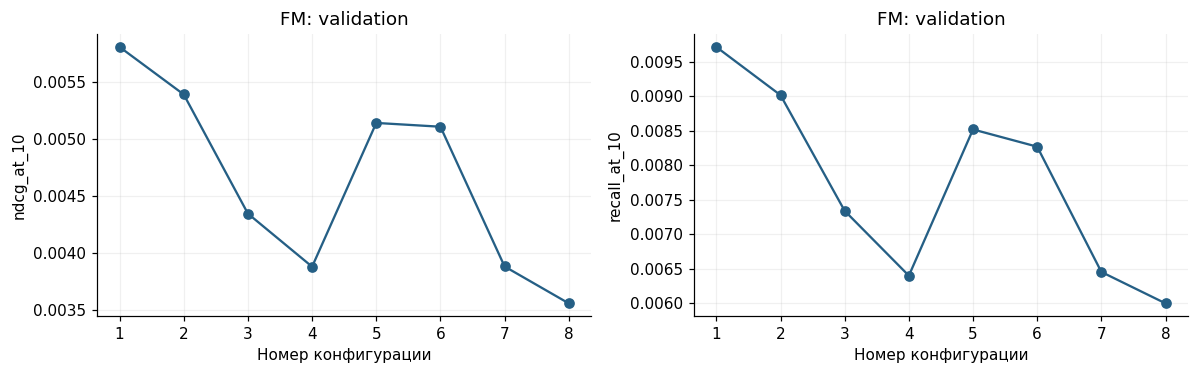

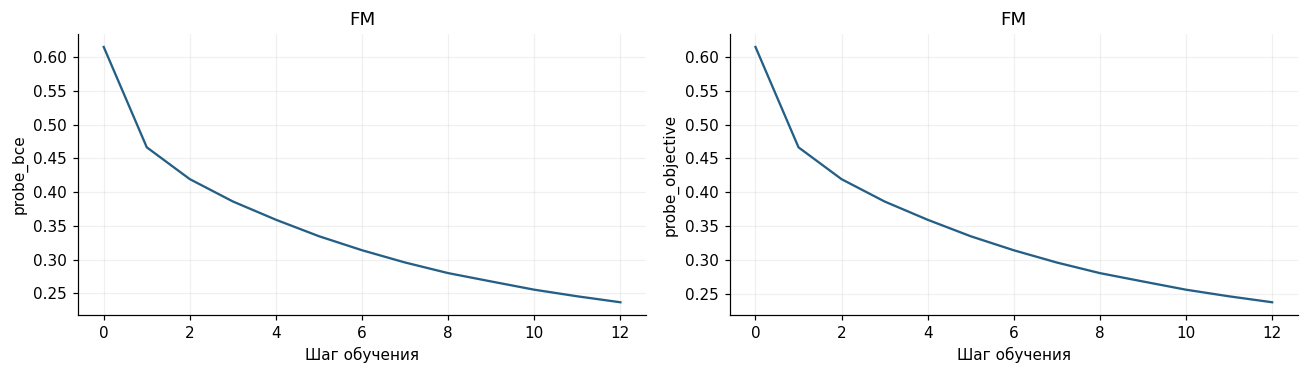

,ndcg_at_10,recall_at_10,catalog_coverage_at_10,fallback_rate,users,evaluation_seconds
model,,,,,,
Popularity,0.005779,0.010252,0.000963,0.000000,10207,1.129206
ItemKNN,0.021111,0.032179,0.738798,0.051435,10207,1.194325
iALS,0.021893,0.034360,0.143215,0.050260,10207,1.483479
EASE,0.023372,0.035191,0.497689,0.051435,10207,1.704717
FM,0.005808,0.009718,0.067724,0.000000,10207,1.419363


,users,ndcg,recall,fallback_rate
history_slice,,,,
1-4,5943,0.005964,0.009215,0.000000
5-9,2766,0.006578,0.012553,0.000000
10+,1498,0.003767,0.006481,0.000000


,users,relevant_interactions,recall_at_10
item_slice,,,
head_top_10_percent,5704,10248,0.022631
tail_other_90_percent,7765,15398,0.000064


In [27]:
plot_search('FM')

Исторические признаки и negative sampling.

In [28]:
display(pd.Series(best_diagnostics['FM'],name='FM').to_frame())

,FM
features,59076
user_id_features,43463
item_id_features,15578
uses_metadata,True
first_year_vocabulary,17
first_month_vocabulary,12
numeric_metadata_features,3
minimum_catalog_items_per_token,5
max_active_item_features,6
query_timestamp,1451606400


FM с метапризнаками и FM только с ID; параметры лучшей FM.

In [29]:
model, _, _, _ = fit_model('FM',best_parameters['FM'],train,train_data,
                          validation_context.query_timestamp,stage='ablation',use_metadata=False)
fm_id_result = evaluate_model(model,validation_context)
del model
gc.collect()
display(pd.DataFrame([{'variant':'FM + metadata',**validation_results['FM'].metrics},
                      {'variant':'FM ID-only',**fm_id_result.metrics}]))

,variant,ndcg_at_10,recall_at_10,catalog_coverage_at_10,fallback_rate,users,evaluation_seconds
0,FM + metadata,0.005808,0.009718,0.067724,0.000000,10207,1.419363
1,FM ID-only,0.005860,0.008941,0.079214,0.000000,10207,1.508656


## timeSVD++

Сетка параметров и подбор по validation NDCG@10.

In [30]:
display(pd.Series(SEARCH['timeSVD++'], name='Параметры').to_frame())
validation_search('timeSVD++')

,Параметры
model,timeSVD++
grid,"{'n_factors': [16, 32], 'n_bins': [12, 36], 'r..."
budget,8
learning_rate,0.050000
n_epochs,50
beta,0.400000
seed,42
target,original observed ratings 1..5; no negative sa...
implicit_history,"all observed fit items, including the rated ta..."
time,UTC integer Unix days; fit-only per-user mean;...


timeSVD++: 1/8 — {'learning_rate': 0.05, 'n_epochs': 50, 'beta': 0.4, 'seed': 42, 'n_factors': 16, 'n_bins': 12, 'regularization': 0.01}


NDCG@10=0.000380; Recall@10=0.000780


timeSVD++: 2/8 — {'learning_rate': 0.05, 'n_epochs': 50, 'beta': 0.4, 'seed': 42, 'n_factors': 16, 'n_bins': 12, 'regularization': 0.1}


NDCG@10=0.000135; Recall@10=0.000218


...

NDCG@10=0.000616; Recall@10=0.000967


timeSVD++: 8/8 — {'learning_rate': 0.05, 'n_epochs': 50, 'beta': 0.4, 'seed': 42, 'n_factors': 32, 'n_bins': 36, 'regularization': 0.1}


NDCG@10=0.000381; Recall@10=0.000561


,trial,learning_rate,n_epochs,beta,seed,n_factors,n_bins,regularization,ndcg_at_10,recall_at_10,catalog_coverage_at_10,fallback_rate,users,evaluation_seconds,fit_seconds
6,7,0.050000,50,0.400000,42,32,36,0.010000,0.000616,0.000967,0.338233,0.000000,10207,1.807382,6.824264
2,3,0.050000,50,0.400000,42,16,36,0.010000,0.000567,0.000938,0.263256,0.000000,10207,1.759189,3.909323
7,8,0.050000,50,0.400000,42,32,36,0.100000,0.000381,0.000561,0.181217,0.000000,10207,1.842584,6.792027
0,1,0.050000,50,0.400000,42,16,12,0.010000,0.000380,0.000780,0.298369,0.000000,10207,1.684032,3.881622
4,5,0.050000,50,0.400000,42,32,12,0.010000,0.000364,0.000706,0.397933,0.000000,10207,1.811162,6.770169
3,4,0.050000,50,0.400000,42,16,36,0.100000,0.000279,0.000386,0.177751,0.000000,10207,1.790268,3.867326
1,2,0.050000,50,0.400000,42,16,12,0.100000,0.000135,0.000218,0.218513,0.000000,10207,1.739735,3.796130
5,6,0.050000,50,0.400000,42,32,12,0.100000,0.000123,0.000194,0.244832,0.000000,10207,1.852325,6.678704


,Лучшие параметры
learning_rate,0.050000
n_epochs,50.000000
beta,0.400000
seed,42.000000
n_factors,32.000000
n_bins,36.000000
regularization,0.010000


Метрики validation, кривая обучения и срезы качества.

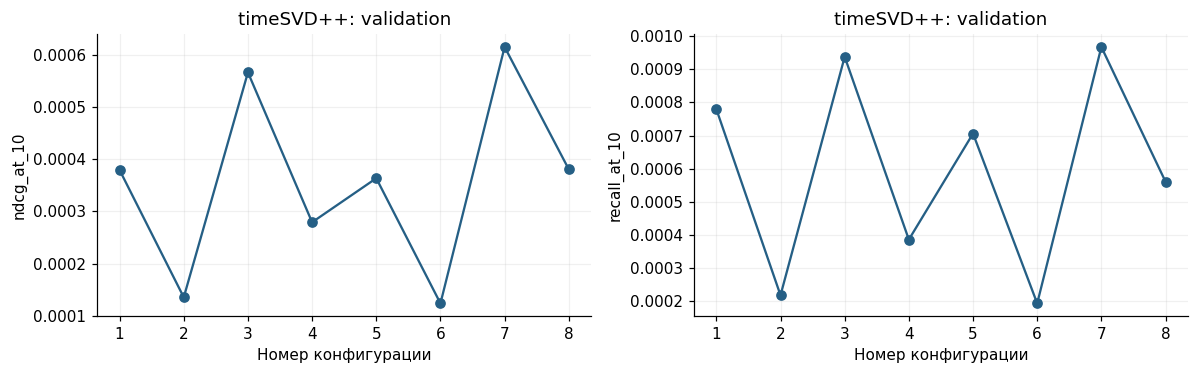

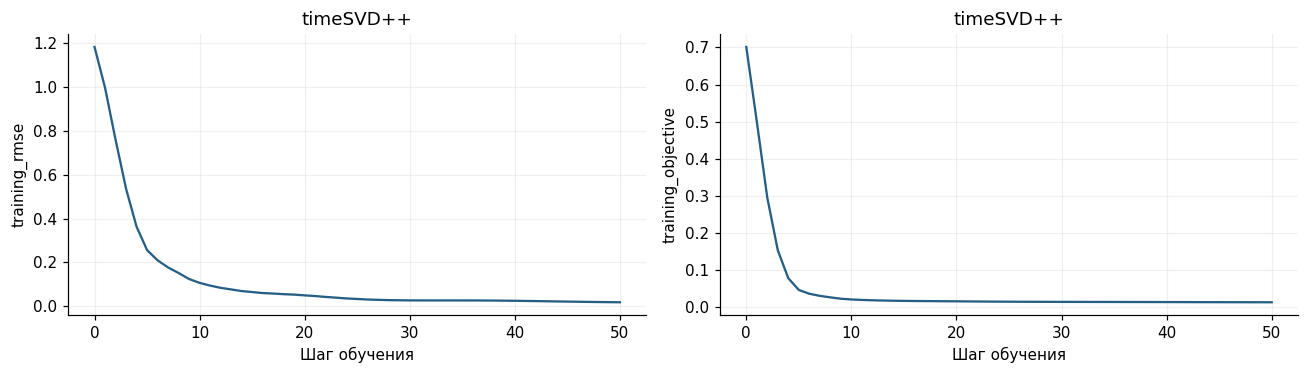

,ndcg_at_10,recall_at_10,catalog_coverage_at_10,fallback_rate,users,evaluation_seconds
model,,,,,,
Popularity,0.005779,0.010252,0.000963,0.000000,10207,1.129206
ItemKNN,0.021111,0.032179,0.738798,0.051435,10207,1.194325
iALS,0.021893,0.034360,0.143215,0.050260,10207,1.483479
EASE,0.023372,0.035191,0.497689,0.051435,10207,1.704717
FM,0.005808,0.009718,0.067724,0.000000,10207,1.419363
timeSVD++,0.000616,0.000967,0.338233,0.000000,10207,1.807382


,users,ndcg,recall,fallback_rate
history_slice,,,,
1-4,5943,0.000488,0.000787,0.000000
5-9,2766,0.000872,0.001265,0.000000
10+,1498,0.000653,0.001135,0.000000


,users,relevant_interactions,recall_at_10
item_slice,,,
head_top_10_percent,5704,10248,0.001624
tail_other_90_percent,7765,15398,0.000558


In [31]:
plot_search('timeSVD++')

timeSVD++ и статическая SVD++; одинаковые параметры.

In [32]:
model, _, _, _ = fit_model('timeSVD++',best_parameters['timeSVD++'],train,train_data,
                          validation_context.query_timestamp,stage='ablation',temporal=False)
time_static_result = evaluate_model(model,validation_context)
del model
gc.collect()
display(pd.DataFrame([{'variant':'timeSVD++',**validation_results['timeSVD++'].metrics},
                      {'variant':'static SVD++',**time_static_result.metrics}]))

,variant,ndcg_at_10,recall_at_10,catalog_coverage_at_10,fallback_rate,users,evaluation_seconds
0,timeSVD++,0.000616,0.000967,0.338233,0.000000,10207,1.807382
1,static SVD++,0.001193,0.002038,0.473552,0.000000,10207,1.622750


## Итоговые выводы

Фиксация параметров после всех validation-подборов.

In [33]:
assert set(best_parameters) == set(MODEL_NAMES)
for name in MODEL_NAMES:
    assert len(searches[name]) == SEARCH[name]['budget']
    assert search_specs[name] == {'grid':SEARCH[name]['grid'], 'fixed':FIXED[name]}
    assert validation_results[name].cohort_fingerprint == validation_context.fingerprint
    row = searches[name].iloc[0]
    assert all(row[key] == value for key,value in best_parameters[name].items())
locked_parameters = json.loads(json.dumps(best_parameters))
reference = max(MODEL_NAMES, key=lambda name: validation_results[name].metrics['ndcg_at_10'])
lock = {'models':locked_parameters,'reference':reference,'selection':'validation NDCG@10',
        'validation_cohort':validation_context.fingerprint,'protocol':protocol}
lock_text = json.dumps(lock,ensure_ascii=False,sort_keys=True,indent=2)
lock_digest = hashlib.sha256(lock_text.encode()).hexdigest()
(RUN/'selected_parameters.json').write_text(lock_text)
display(pd.DataFrame(locked_parameters).T)
print('Validation reference:', reference)
print('Parameter lock SHA-256:', lock_digest)

,n_neighbors,shrinkage,n_iterations,seed,solver_batch_size,n_factors,alpha,regularization,n_epochs,batch_size,shuffle_seed,learning_rate,beta,n_bins
ItemKNN,100.000000,10.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
iALS,NaN,NaN,15.000000,42.000000,128.000000,64.000000,40.000000,0.100000,NaN,NaN,NaN,NaN,NaN,NaN
EASE,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.000000,NaN,NaN,NaN,NaN,NaN,NaN
FM,NaN,NaN,NaN,42.000000,NaN,16.000000,NaN,0.000010,12.000000,1024.000000,43.000000,0.050000,NaN,NaN
timeSVD++,NaN,NaN,NaN,42.000000,NaN,32.000000,NaN,0.010000,50.000000,NaN,NaN,0.050000,0.400000,36.000000


Validation reference: EASE
Parameter lock SHA-256: ca5d14a8043aec3fd012b64a6e1061fdf323ed95af0377eed6e670332ef56ada


Обучение пяти моделей на train + validation и финальные test-метрики.

In [34]:
assert hashlib.sha256((RUN/'selected_parameters.json').read_bytes()).hexdigest() == lock_digest
final_data = FitData.from_frame(final_fit)
test_context = EvaluationContext.from_frames(final_fit,test,fit_data=final_data,
                         k=K,query_timestamp=int(TEST_START.timestamp()))
test_results = {'Popularity':evaluate_popularity(test_context)}
final_fit_seconds = {'Popularity':0.}
for name in MODEL_NAMES:
    print(f'Final fit: {name}',flush=True)
    model, seconds, _, _ = fit_model(name,locked_parameters[name],final_fit,final_data,
                                   test_context.query_timestamp,stage='final')
    test_results[name] = evaluate_model(model,test_context,batch_size=128)
    final_fit_seconds[name] = seconds
    del model
    gc.collect()
assert set(test_results) == set(MODEL_NAMES)|{'Popularity'}
assert sum(row['stage']=='final' for row in fit_log) == 5
assert sum(row['stage']=='validation' for row in fit_log) == sum(c['budget'] for c in SEARCH.values())
assert all(r.cohort_fingerprint==test_context.fingerprint for r in test_results.values())
assert all(row['max_fit_timestamp'] < row['query_timestamp'] for row in fit_log)
final_table = pd.DataFrame([{'model':name,**result.metrics,'fit_seconds':final_fit_seconds[name]}
                           for name,result in test_results.items()]).set_index('model')
validation_table = pd.DataFrame([{'model':name,**result.metrics} for name,result in validation_results.items()]).set_index('model')
comparison = pd.concat({'validation':validation_table[['ndcg_at_10','recall_at_10']],
                        'test':final_table[['ndcg_at_10','recall_at_10']]},axis=1)
display(pd.Series(test_context.diagnostics,name='Test').to_frame())
display(comparison)
comparison.to_csv(RUN/'comparison.csv')
final_table.to_csv(RUN/'test_metrics.csv')
(RUN/'fit_log.json').write_text(json.dumps(fit_log,ensure_ascii=False,indent=2))
for name,result in test_results.items():
    result.per_user.to_csv(RUN/f'{name.replace("+","p")}_test_users.csv.gz')

Final fit: ItemKNN


Final fit: iALS


Final fit: EASE


Final fit: FM


Final fit: timeSVD++


,Test
evaluation_users,9521
catalog_items,16721
relevant_interactions,23454
seen_relevant_items_removed,0
users_excluded_for_fewer_than_k_candidates,0
new_user_interactions,16023
new_item_interactions,4423


validation                    test             
           ndcg_at_10 recall_at_10 ndcg_at_10 recall_at_10
model                                                     
Popularity   0.005779     0.010252   0.009712     0.012274
ItemKNN      0.021111     0.032179   0.021241     0.032328
iALS         0.021893     0.034360   0.022217     0.034842
EASE         0.023372     0.035191   0.022048     0.033390
FM           0.005808     0.009718   0.006611     0.010603
timeSVD++    0.000616     0.000967   0.000579     0.001113

Validation и test: NDCG@10 и Recall@10.

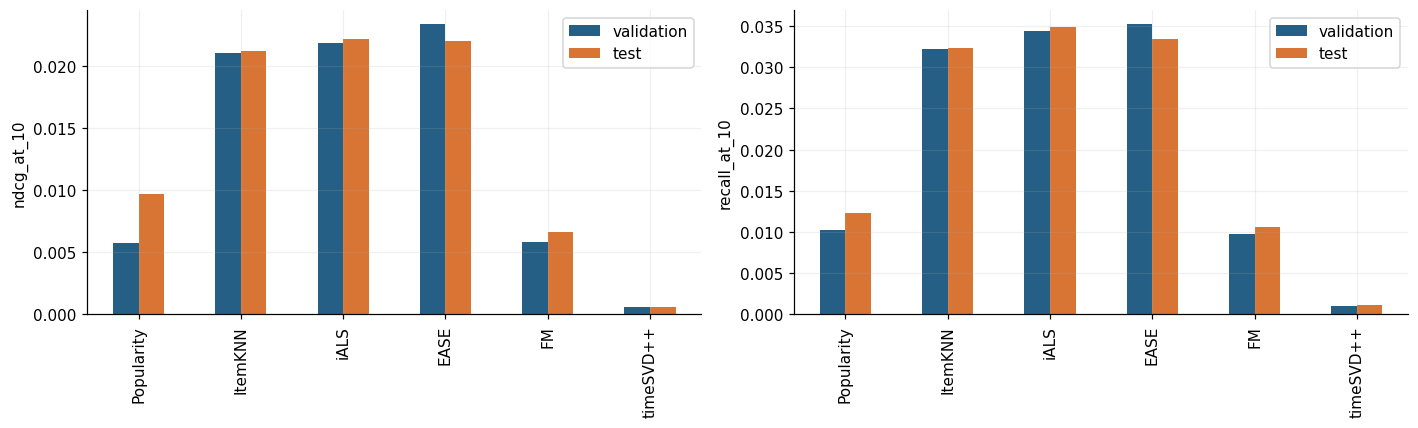

In [35]:
fig,axes=plt.subplots(1,2,figsize=(13,4))
for ax,metric in zip(axes,['ndcg_at_10','recall_at_10']):
    pd.DataFrame({'validation':validation_table[metric],'test':final_table[metric]}).plot.bar(ax=ax)
    ax.set(ylabel=metric,xlabel='')
show_figure('validation_test',fig)

Парные доверительные интервалы относительно validation-лидера.

,model,metric,estimate_for,estimate,ci_low,ci_high
2,Popularity,ndcg_at_10,difference,-0.012336,-0.014643,-0.009981
5,Popularity,recall_at_10,difference,-0.021116,-0.024299,-0.017868
8,ItemKNN,ndcg_at_10,difference,-0.000807,-0.001768,0.000217
11,ItemKNN,recall_at_10,difference,-0.001062,-0.002773,0.000774
14,iALS,ndcg_at_10,difference,0.000169,-0.001465,0.001961
17,iALS,recall_at_10,difference,0.001452,-0.001359,0.004324
20,FM,ndcg_at_10,difference,-0.015436,-0.017508,-0.013404
23,FM,recall_at_10,difference,-0.022787,-0.025950,-0.019790
26,timeSVD++,ndcg_at_10,difference,-0.021469,-0.023387,-0.019520
29,timeSVD++,recall_at_10,difference,-0.032277,-0.035190,-0.029425


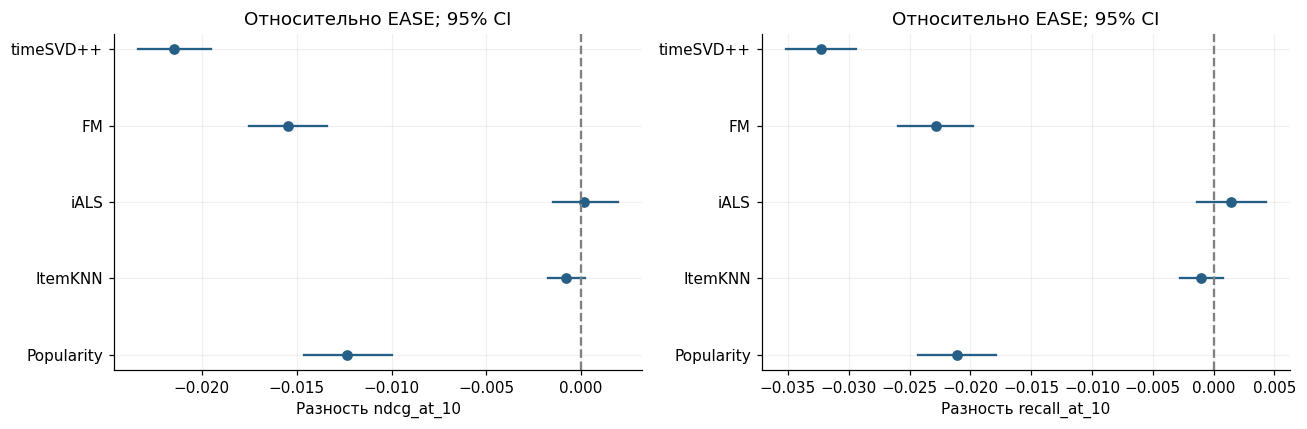

In [36]:
interval_tables=[]
for name,result in test_results.items():
    if name == reference:
        continue
    table=paired_bootstrap(result,test_results[reference],resamples=2000,seed=SEED,
                           confidence=.95,result_name=name,baseline_name=reference)
    table.insert(0,'model',name)
    interval_tables.append(table)
intervals=pd.concat(interval_tables,ignore_index=True)
differences=intervals[intervals.estimate_for=='difference'].copy()
display(differences)
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,metric in zip(axes,['ndcg_at_10','recall_at_10']):
    table=differences[differences.metric==metric]
    for pos,row in enumerate(table.itertuples()):
        ax.plot([row.ci_low,row.ci_high],[pos,pos],color=COLORS[0])
        ax.plot(row.estimate,pos,'o',color=COLORS[0])
    ax.set_yticks(range(len(table)),table.model)
    ax.axvline(0,color='gray',linestyle='--')
    ax.set(xlabel=f'Разность {metric}',title=f'Относительно {reference}; 95% CI')
show_figure('intervals',fig)
intervals.to_csv(RUN/'bootstrap.csv',index=False)

Срезы test по истории и популярности, покрытие каталога и время обучения.

users     ndcg   recall  fallback_rate
model      history_slice                                        
Popularity 1-4             4561 0.009973 0.012498       0.000000
           5-9             3149 0.008969 0.011169       0.000000
           10+             1811 0.010345 0.013631       0.000000
ItemKNN    1-4             4561 0.023038 0.033194       0.067310
           5-9             3149 0.019291 0.031996       0.005399
           10+             1811 0.020105 0.030724       0.000000
iALS       1-4             4561 0.025259 0.037720       0.065775
           5-9             3149 0.020026 0.033892       0.005399
           10+             1811 0.018363 0.029246       0.000000
EASE       1-4             4561 0.024040 0.033743       0.067310
           5-9             3149 0.020436 0.033490       0.005399
           10+             1811 0.019831 0.032327       0.000000
FM         1-4             4561 0.006794 0.010981       0.000000
           5-9             3149 0.005446 0.008973       0.000000
           10+             1811 0.008176 0.012484       0.000000
timeSVD++  1-4             4561 0.000307 0.000488       0.000000
           5-9             3149 0.000390 0.000926       0.000000
           10+             1811 0.001592 0.003013       0.000000

users  relevant_interactions  recall_at_10
model      item_slice                                                       
Popularity head_top_10_percent     5572                  10028      0.027900
           tail_other_90_percent   7063                  13426      0.000000
ItemKNN    head_top_10_percent     5572                  10028      0.056127
           tail_other_90_percent   7063                  13426      0.013090
iALS       head_top_10_percent     5572                  10028      0.077209
           tail_other_90_percent   7063                  13426      0.002494
EASE       head_top_10_percent     5572                  10028      0.064549
           tail_other_90_percent   7063                  13426      0.009704
FM         head_top_10_percent     5572                  10028      0.025591
           tail_other_90_percent   7063                  13426      0.000203
timeSVD++  head_top_10_percent     5572                  10028      0.001546
           tail_other_90_percent   7063                  13426      0.000549

,catalog_coverage_at_10,fallback_rate,fit_seconds,evaluation_seconds
model,,,,
Popularity,0.001076,0.000000,0.000000,1.397611
ItemKNN,0.674242,0.034030,0.408834,1.194193
iALS,0.135040,0.033295,49.524526,1.660626
EASE,0.442378,0.034030,20.214333,1.750378
FM,0.067699,0.000000,19.556746,1.449353
timeSVD++,0.348185,0.000000,8.556005,1.629566


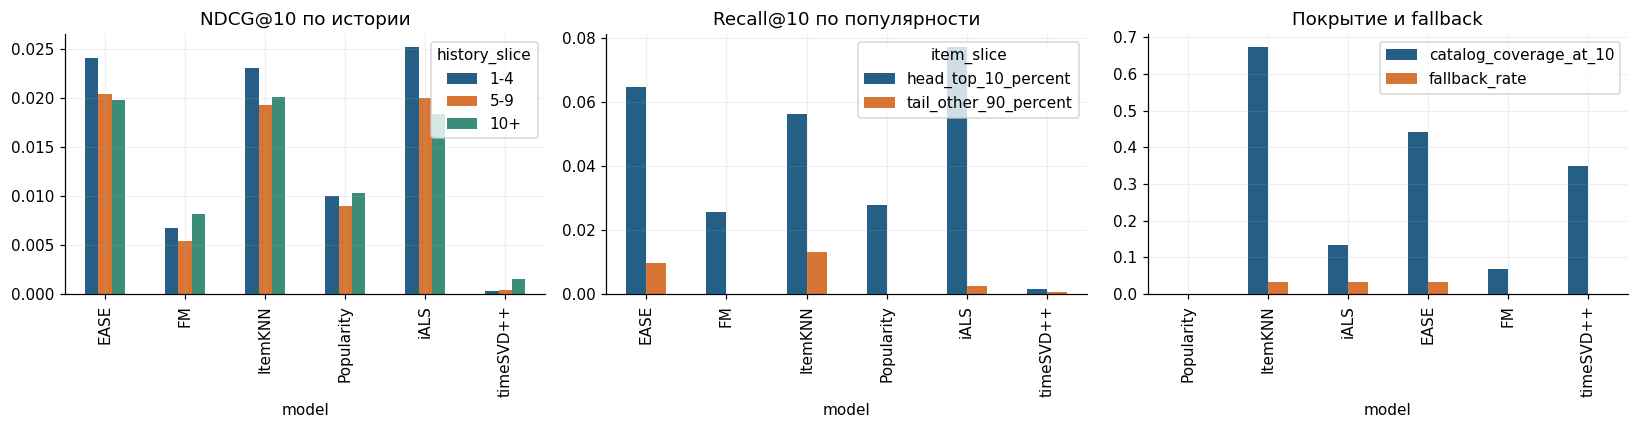

In [37]:
history=pd.concat({name:history_slices(result) for name,result in test_results.items()},names=['model'])
popularity=pd.concat({name:popularity_slices(result,test_context) for name,result in test_results.items()},names=['model'])
display(history)
display(popularity)
display(final_table[['catalog_coverage_at_10','fallback_rate','fit_seconds','evaluation_seconds']])
fig,axes=plt.subplots(1,3,figsize=(15,4))
history.reset_index().pivot(index='model',columns='history_slice',values='ndcg').plot.bar(ax=axes[0])
popularity.reset_index().pivot(index='model',columns='item_slice',values='recall_at_10').plot.bar(ax=axes[1])
final_table[['catalog_coverage_at_10','fallback_rate']].plot.bar(ax=axes[2])
axes[0].set_title('NDCG@10 по истории')
axes[1].set_title('Recall@10 по популярности')
axes[2].set_title('Покрытие и fallback')
show_figure('slices',fig)

Итоговые метрики, вклад метапризнаков и ограничения.

In [38]:
leader=final_table.loc[MODEL_NAMES,'ndcg_at_10'].idxmax()
fm_delta=validation_results['FM'].metrics['ndcg_at_10']-fm_id_result.metrics['ndcg_at_10']
time_delta=validation_results['timeSVD++'].metrics['ndcg_at_10']-time_static_result.metrics['ndcg_at_10']
display(Markdown(f'Лучший validation NDCG@10: **{reference}**. '
    f'Наибольший test NDCG@10: **{leader}** ({final_table.loc[leader,"ndcg_at_10"]:.6f}).\n\n'
    f'Вклад метапризнаков FM в validation NDCG@10: **{fm_delta:+.6f}**. '
    f'Вклад временных компонент timeSVD++: **{time_delta:+.6f}**.\n\n'
    'FM: BCE и sampled negatives; timeSVD++: ошибка оценок. '
    'Несовпадение целей обучения с top-10 ранжированием; ограниченные сетки; один seed. '
    'Bootstrap-интервалы — по пользователям, без поправки на множественные сравнения.\n\n'
    'Исходный test — ранее использованный holdout. Текущий запуск — воспроизведение v2. '
    '[Отдельная внешняя оценка за 2019 год](https://github.com/noobmaster-ru/recsys_cmc_msu_2026_course/tree/7191c2e526c7f198871bbca56474f77c73d66bbe/homework_1/external_2019).'))

Лучший validation NDCG@10: **EASE**. Наибольший test NDCG@10: **iALS** (0.022217).

Вклад метапризнаков FM в validation NDCG@10: **-0.000052**. Вклад временных компонент timeSVD++: **-0.000577**.

FM: BCE и sampled negatives; timeSVD++: ошибка оценок. Несовпадение целей обучения с top-10 ранжированием; ограниченные сетки; один seed. Bootstrap-интервалы — по пользователям, без поправки на множественные сравнения.

Исходный test — ранее использованный holdout. Текущий запуск — воспроизведение v2. [Отдельная внешняя оценка за 2019 год](https://github.com/noobmaster-ru/recsys_cmc_msu_2026_course/tree/7191c2e526c7f198871bbca56474f77c73d66bbe/homework_1/external_2019).